# Predicción de riesgo coronario a 10 años — Modelos de machine learning, evaluación y discusión

**Entrega 2 (preprocesamiento, metodología, modelos, análisis y discusión)**

Este notebook continúa el trabajo de la Parte 1 (`01-eda.ipynb`), que analiza y explora los datos
del *Framingham Heart Study*. Aquí se ponen en práctica las decisiones tomadas en el EDA, se
construyen modelos de machine learning que resuelven el problema, se evalúan sus resultados y se
discuten las conclusiones. El notebook se organiza en 13 secciones: recapitulación del EDA (0),
carga (1), partición (2), preprocesamiento (3), metodología (4), ajuste de hiperparámetros (5),
selección del modelo (6), umbral de decisión (7), evaluación final (8), interpretación (9), análisis
de errores (10), equidad (11) y síntesis (12). Al final se listan las referencias citadas en el texto.

| Rol | Modelo |
| --- | --- |
| Baseline trivial | `DummyClassifier` (predice la proporción de positivos) |
| Baseline informado | Regresión logística solo con `age` |
| Lineal | Regresión logística regularizada (L2) |
| No lineal | Random Forest |
| No lineal | Gradient Boosting (`HistGradientBoostingClassifier`) |

**Diseño experimental, fijado antes de ver ningún resultado:** un único *split* estratificado 80/20
(el 20 % de prueba se usa una sola vez, al final); todo el preprocesamiento dentro de un `Pipeline`;
validación cruzada estratificada de 5 pliegues sobre el entrenamiento para ajustar hiperparámetros,
decidir el manejo del desbalance, elegir el modelo y elegir el umbral; **PR-AUC** como métrica
principal (ROC-AUC como secundaria); e intervalos de confianza por *bootstrap* en la evaluación final.

## 0. El análisis de la Parte 1

Del EDA realizado en la Parte 1 se obtuvo lo siguiente:

* **Tamaño del dataset y objetivo.** 4 240 participantes, 15 variables predictoras  y una variable 
  objetivo (`TenYearCHD`) que indica la presencia o ausencia de una enfermedad coronaria en 10 años.
* **Desbalance** De los 4 240 participantes el 15,19 % desarrolló enfermedad coronaria. Es decir, en el dataset
    hay casi 6 personas sanas por 1 persona enferma. Predecir siempre "sin enfermedad" da 84,8% de exactitud, por lo 
    que la exactitud **no** sirve como criterio de éxito.
* **Faltantes.** 13,73 % de las filas contiene al menos un faltante, la variable con más faltantes es `glucose`
  (9,15 %). 
* **Atípicos.** Los valores atípicos son clínicamente posibles (glucosa hasta 394 mg/dL, IMC hasta 56,8, sistólica
  hasta 295 mm Hg), por lo que se van a **conservar**.
* **Redundancia entre predictores.** `sysBP`–`diaBP` (0,78), `cigsPerDay`–`currentSmoker` (0,77),
  `sysBP`–`prevalentHyp` (0,70), `glucose`–`diabetes` (0,62). Son variables que representan resúmenes clínicos parcialmente
  redundantes.
* **Correlación individual baja.** Ninguna variable supera una correlación de 0,23 con la variable objetivo

## 1. Carga de Datos 

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# permite importar src/ tanto si el notebook se ejecuta desde notebooks/ como desde la raíz
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from sklearn.base import clone
from sklearn.model_selection import (train_test_split, StratifiedKFold, GridSearchCV,
                                     cross_validate, cross_val_predict)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, fbeta_score,
                             roc_auc_score, average_precision_score, brier_score_loss,
                             confusion_matrix, precision_recall_curve, roc_curve)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

# constantes compartidas del proyecto (rutas, semilla, grupos de variables)
from src.config import DATA_PATH, TARGET, SEED, NUM, BIN, ORD
from src.plotting import use_style, guardar

use_style("notes")
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 20)

FEATURES = NUM + BIN + ORD
TEST_SIZE = 0.2   # partición 80/20
N_FOLDS = 5       # validación cruzada de 5 pliegues

TABLE_DIR = ROOT / "results" / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
COLORES = {"Regresión logística": "#0072B2", "Random Forest": "#009E73", "Gradient Boosting": "#D55E00",
           "Logística solo edad": "#999999"}

raw = pd.read_csv(DATA_PATH)
print("dataset:", raw.shape[0], "participantes x", raw.shape[1], "columnas")

dataset: 4240 participantes x 16 columnas


## 2. Partición de los datos

### 2.1 Partición train / test

La partición de los datos se hace **antes de cualquier modificación**. Se realiza para evitar
el *data leakage*: cualquier estadística que se calcule después debe salir solo del conjunto de 
entrenamiento. Si no se realizara la partición, la información de los datos de prueba se filtraría
hacia el entrenamiento y las métricas saldrían optimistas.

A considerar:
* **Estratificación**: para que ambos subconjuntos conserven la proporción de aproximadamente 15 % de positivos 
  se necesita estratificar por la variable objetivo. Sin estratificar, con tan pocos positivos, el conjunto de prueba podría
  quedar con una proporción muy distinta.
* **80 % train / 20 % test**, como se propuso en la Parte 1. Con 644 eventos en total, el 20 % de prueba
  deja 129 eventos, suficientes para estimar las métricas finales con intervalos de confianza útiles, y
  conserva 515 eventos para entrenar y validar. Un test del 10 % (unos 65 eventos) daría intervalos
  demasiado anchos; uno del 30 % restaría casos al ajuste de los modelos.
* El conjunto de test **no se vuelve a tocar**, ni para elegir hiperparámetros, 
  ni para comparar modelos, etc. Estas decisiones se realizan con cross validation sobre el conjunto de train

In [2]:
X = raw[FEATURES].copy()
y = raw[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=TEST_SIZE,stratify=y,random_state=SEED,)
print(f"train: {X_train.shape[0]} filas  |  test: {X_test.shape[0]} filas")
print(f"% positivos  ->  total: {100 * y.mean():.2f}  |  train: {100 * y_train.mean():.2f}  |  test: {100 * y_test.mean():.2f}")

train: 3392 filas  |  test: 848 filas
% positivos  ->  total: 15.19  |  train: 15.18  |  test: 15.21


### 2.2 CrossValidation Estratificado

Como se mencionó para comparar modelos y ajustar hiperparámetros se usa **crossvalidation de 5
pliegues** sobre el conjunto de train, por dos razones:

* **Estratificada**, porque con 15 % de positivos un pliegue aleatorio podría quedar con muy pocos
  casos de la clase minoritaria y producir métricas inestables.
* **Con shuffle y semilla fija** (`shuffle=True`, `random_state=SEED`), para que todos los
  modelos se evalúen sobre **exactamente los mismos pliegues**. Así las diferencias entre modelos
  reflejan al modelo y no el azar de la partición.
* **Cinco pliegues y no diez**: con 515 positivos en entrenamiento, cada pliegue de validación tiene
  unos 103 eventos; con diez pliegues serían unos 52 y la PR-AUC de cada pliegue sería bastante más
  ruidosa. Cinco pliegues es el compromiso habitual entre entrenar con suficientes datos en cada ronda
  (80 % del entrenamiento) y obtener una estimación estable.

In [3]:
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)

# tamaño y variable objetiva en cada pliegue, solo para verificar que esten balanceados
filas = []
for k, (idx_tr, idx_val) in enumerate(cv.split(X_train, y_train), start=1):
    filas.append({"pliegue": k,
                  "n entrena": len(idx_tr), "n valida": len(idx_val),
                  "% positivos (entrena)": 100 * y_train.iloc[idx_tr].mean(),
                  "% positivos (valida)":  100 * y_train.iloc[idx_val].mean()})
pd.DataFrame(filas).set_index("pliegue").round(2)

,n entrena,n valida,% positivos (entrena),% positivos (valida)
pliegue,,,,
1,2713,679,15.19,15.17
2,2713,679,15.19,15.17
3,2714,678,15.18,15.19
4,2714,678,15.18,15.19
5,2714,678,15.18,15.19


La estratificación conserva la proporción de eventos casi exacta: 15,18 % en entrenamiento
(515 de 3 392) y 15,21 % en prueba (129 de 848), y cada uno de los cinco pliegues queda entre
15,17 % y 15,19 %. El conjunto de prueba tiene solo 129 eventos, de modo que cada caso detectado o
perdido mueve el recall en 0,78 puntos porcentuales; por eso la evaluación final incluye intervalos
de confianza (sección 8.1).

## 3. Preprocesamiento e ingeniería de características

Esta sección convierte `X_train` en una matriz que pueda ser fácilmente usada por los modelos
de machine learning. Cada decisión para procesar los datos viene de haber realizado el EDA en la Parte 1.
Todo el procesamiento está estructurado mediante un `Pipeline` de *scikit-learn*, lo que garantiza la ausencia de data leakage y permite 
reutilizar la misma cadena en pasos posteriores


### 3.1 Resumen

| Variables | ¿Qué se hizo? | Justificación |
| --- | --- | --- |
| `glucose`, `totChol`, `BMI` ( datos faltantes) | Se rellenan con la mediana de su mismo sexo  | Los datos que faltan se parecen más a los de su grupo por sexo que a los de toda la muestra. |
| `cigsPerDay` ( datos faltantes) | Se pone 0 si la persona no fuma. Si fumará, se usa la mediana de los fumadores | Si la persona no fuma, su `cigsPerDay` debe ser 0 |
| `education`, `BPMeds` (datos faltantes) | Se rellenan con el valor más frecuente | Son variables categóricas así que asignarle el valor más frecuente no cambia mucho el análisis |
| `heartRate` (datos faltantes) | Se rellena con la mediana de todos | Esta variable solo falta un dato, asi que no influye mucho |
| Variables numéricas | Se escalan con `RobustScaler` | Deja todas en una escala parecida usando la mediana y el rango intercuartílico. Así los valores muy altos de `glucose`  no distorsionan al resto |
| Variables binarias y `education` | No se transforman | Las binarias ya están en 0/1, y `education` se deja como número de 1 a 4 para respetar su orden |
| Presión de pulso (variable nueva, `pulsePressure`) | Se crea como `sysBP` − `diaBP` | Mide la rigidez de las arterias principales. Resumirá en un solo número la diferencia entre las dos presiones |

Las clases y la función que construyen este preprocesamiento están en `src/preprocessing.py`, para que el notebook y cualquier otro script usen exactamente el mismo código.

### 3.2 Presión de pulso

La **presión de pulso** es un indicador clínico de la rigidez de las arterias. Se calcula fila por fila, 
y es una simple resta de 2 variables ya existentes en el dataset: `sysBP` y `diaBP`


In [4]:
from src.preprocessing import AnadirPresionPulso, ImputarFaltantes, build_preprocessor

# temp es una copia de X_train agregando la nueva columna
tmp = X_train.assign(pulsePressure=X_train["sysBP"] - X_train["diaBP"])
columnas = ["sysBP","diaBP","pulsePressure"]

# se crea un dataset para analizar la tabla de correlaciones
pd.DataFrame({
    # calculamos la correlacion de sysBP, diaBP y pulsePressure con la variable objetivo
    "corr con TenYearCHD":tmp[columnas].corrwith(y_train),

    # calculamos la correlación de las 3 variables contra sysBP.
    "corr con sysBP":tmp[columnas].corrwith(tmp["sysBP"]),

    # calculamos la correlación de las 3 variables contra diaBP.
    "corr con diaBP":tmp[columnas].corrwith(tmp["diaBP"]),
}).round(3)

,corr con TenYearCHD,corr con sysBP,corr con diaBP
sysBP,0.227,1.000,0.786
diaBP,0.158,0.786,1.000
pulsePressure,0.213,0.865,0.369


La presión de pulso tiene una correlación de 0,213 con `TenYearCHD`, casi igual a la de `sysBP`
(0,227) y mayor que la de `diaBP` (0,158). Se parece poco a `diaBP` (0,369), pero bastante a `sysBP`
(0,865), por lo que no es una variable independiente: resume la diferencia entre las dos presiones.

Al ser una combinación lineal exacta de `sysBP` y `diaBP`, no le aporta información nueva a un modelo
lineal que ya incluye ambas presiones (la logística puede representar esa resta por su cuenta). Para
un modelo de árboles, que divide variable por variable y no calcula restas, sí puede ser útil. La
sección 6.2 mide su aporte real.

### 3.3 Valores faltantes

En lugar de eliminar filas por valores faltantes, se utilizará un transformador propio para imputarlos. Este aprenderá las medianas y modas únicamente del conjunto recibido en fit, lo que garantiza que dentro de la validación cruzada solo se calculen a partir de los pliegues de entrenamiento.

La clase `ImputarFaltantes` está en `src/preprocessing.py`; la celda siguiente la ajusta con el conjunto de entrenamiento y muestra lo que aprendió.

In [5]:
imp = ImputarFaltantes().fit(X_train)

aprendidos = pd.DataFrame(imp.med_sexo_).rename(index={0: "mujer", 1: "hombre"}).round(1)
aprendidos.loc["global"] = {c: round(imp.med_global_[c], 1) for c in aprendidos.columns}
print("medianas aprendidas (train):")
print(aprendidos.to_string())
print("cigsPerDay (mediana de fumadores):", imp.cigs_fumador_)
print("modas:", imp.moda_)

medianas aprendidas (train):
        glucose  totChol   BMI
mujer      78.0    237.0  24.8
hombre     78.0    230.0  26.0
global     78.0    234.0  25.4
cigsPerDay (mediana de fumadores): 20.0
modas: {'education': np.float64(1.0), 'BPMeds': np.float64(0.0)}


### 3.4 Codificación y escalamiento

* **Binarias** (las 6 variables): se dejarán tal cual
* **education**: variable ordinal de 1 a 4, se mantiene como una sola columna numérica. Esto preserva el orden implícito de los niveles y evita añadir tres columnas dummy sobre aproximadamente 3 400 observaciones.
* **Numéricas continuas** (las 8 originales + pulsePressure): se utiliza RobustScaler, el cual centra con la mediana y escala mediante el rango intercuartílico. Se prefiere sobre StandardScaler debido a que se conservan los valores atípicos.

**Orden de los pasos.** Las tres transformaciones se encadenan en un único `Pipeline`, en este orden:

1. **Presión de pulso.** Va primero porque debe calcularse en mm Hg, con los valores originales de
   `sysBP` y `diaBP`. Si se calculara después del escalado, sería una resta de valores ya
   transformados y perdería su significado clínico. Además, al crearse antes del escalado, recibe el
   mismo `RobustScaler` que las demás numéricas.
2. **Imputación.** Va antes del escalado porque sus reglas usan los valores originales: la mediana se
   calcula por sexo (`male` = 0/1) y `cigsPerDay` depende de `currentSmoker` = 0/1, y las medianas
   aprendidas quedan en unidades clínicas (por ejemplo, 78 mg/dL de glucosa), fáciles de revisar.
   Además, la regresión logística no acepta valores faltantes, así que deben estar resueltos antes de
   llegar al modelo.
3. **Escalado.** Va al final para que vea las columnas definitivas (incluida `pulsePressure`) y ya sin
   faltantes. Un `ColumnTransformer` aplica `RobustScaler` solo a las numéricas y deja pasar sin cambios
   a las binarias y a `education`, de modo que en la regresión logística el coeficiente de una binaria
   sigue significando "presencia frente a ausencia".

La tabla siguiente resume qué le ocurre a cada columna. Se construye leyendo los propios pasos del
pipeline, así que refleja exactamente lo que hace el código.


In [6]:
# preprocesamiento completo: AnadirPresionPulso -> ImputarFaltantes -> escalado
preproc = build_preprocessor()

# qué le ocurre a cada columna, leído de los pasos del propio pipeline
pasos_imp = preproc.named_steps["imputar"]
escalado_de = {col: ("RobustScaler (mediana e IQR)" if nombre == "num" else "sin cambios")
               for nombre, _, cols in preproc.named_steps["escalar"].transformers for col in cols}


def regla_imputacion(col):
    if col in pasos_imp.cols_por_sexo:
        return "mediana de su sexo"
    if col == "cigsPerDay":
        return "0 si no fuma; mediana de fumadores si fuma"
    if col in pasos_imp.cols_moda:
        return "valor más frecuente"
    if col in pasos_imp.cols_global:
        return "mediana global"
    return "no tiene faltantes"


def tipo(col):
    if col == "pulsePressure":
        return "derivada (sysBP − diaBP)"
    return "numérica" if col in NUM else ("binaria" if col in BIN else "ordinal")


columnas = list(escalado_de)
pd.DataFrame({
    "tipo": [tipo(c) for c in columnas],
    "faltantes en train": [int(X_train[c].isna().sum()) if c in X_train else 0 for c in columnas],
    "1. imputación": [regla_imputacion(c) if c in X_train and X_train[c].isna().any() else "no tiene faltantes"
                      for c in columnas],
    "2. escalado": [escalado_de[c] for c in columnas],
}, index=pd.Index(columnas, name="columna"))

,tipo,faltantes en train,1. imputación,2. escalado
columna,,,,
age,numérica,0,no tiene faltantes,RobustScaler (mediana e IQR)
totChol,numérica,37,mediana de su sexo,RobustScaler (mediana e IQR)
sysBP,numérica,0,no tiene faltantes,RobustScaler (mediana e IQR)
diaBP,numérica,0,no tiene faltantes,RobustScaler (mediana e IQR)
BMI,numérica,18,mediana de su sexo,RobustScaler (mediana e IQR)
heartRate,numérica,1,mediana global,RobustScaler (mediana e IQR)
glucose,numérica,321,mediana de su sexo,RobustScaler (mediana e IQR)
cigsPerDay,numérica,23,0 si no fuma; mediana de fumadores si fuma,RobustScaler (mediana e IQR)
pulsePressure,derivada (sysBP − diaBP),0,no tiene faltantes,RobustScaler (mediana e IQR)


### 3.5 Verificación del preprocesamiento

Se ajusta el pipeline **solo con `X_train`** y se aplica a train y a test, para comprobar que corre de principio a fin y que no quedan valores faltantes. Más adelante, `preproc` se encadena con cada modelo y la validación cruzada lo vuelve a ajustar en cada pliegue.

In [7]:
Xtr = preproc.fit(X_train).transform(X_train)
Xte = preproc.transform(X_test)

assert Xtr.isna().sum().sum() == 0 and Xte.isna().sum().sum() == 0
print("train:", Xtr.shape, "  test:", Xte.shape)
print("columnas:", list(Xtr.columns))

train: (3392, 16)   test: (848, 16)
columnas: ['age', 'totChol', 'sysBP', 'diaBP', 'BMI', 'heartRate', 'glucose', 'cigsPerDay', 'pulsePressure', 'male', 'currentSmoker', 'BPMeds', 'prevalentStroke', 'prevalentHyp', 'diabetes', 'education']


## 4. Metodología y modelos

Esta sección presenta los modelos que se compararán y justifica su elección. Todos reciben los datos a través del mismo `preproc` y se evalúan con el mismo esquema de validación cruzada `cv` , por lo que las diferencias entre ellos se deben al modelo .

### 4.1 Baselines

Un baseline es el punto de referencia mínimo: si un modelo no lo supera con claridad, no aporta valor. Se usan dos:

| Baseline | Qué hace | Para qué sirve |
| --- | --- | --- |
| **Trivial** (`DummyClassifier`) | Predice siempre la proporción de positivos del entrenamiento (15 %), sin mirar ninguna variable | La exactitud ya sería ~85 % por eso es que no se usa como criterio |
| **Regresión logística solo con `age`** | Un modelo lineal con una única variable, la de mayor correlación con el objetivo | Mide cuánto se gana al usar las demás variables frente a la mejor señal individual |

In [8]:
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# --- baselines ---
baseline_trivial = Pipeline([
    ("preproc", preproc),
    ("modelo", DummyClassifier(strategy="prior")),
])

baseline_age = Pipeline([
    ("solo_age", ColumnTransformer([("age", RobustScaler(), ["age"])])),
    ("modelo", LogisticRegression(max_iter=1000)),
])

In [9]:
SCORING = {"pr_auc": "average_precision", "roc_auc": "roc_auc"}


def pipeline(modelo, **kwargs):
    # preprocesamiento + modelo en un solo estimador: se re-ajusta completo en cada pliegue
    return Pipeline([("preproc", build_preprocessor(**kwargs)), ("modelo", modelo)])


def resumen_cv(est):
    r = cross_validate(est, X_train, y_train, cv=cv, scoring=SCORING)
    return {"PR-AUC (CV)": r["test_pr_auc"].mean(), "± DE": r["test_pr_auc"].std(),
            "ROC-AUC (CV)": r["test_roc_auc"].mean()}


filas = {}
for nombre, est in [("Baseline trivial", baseline_trivial), ("Logística solo edad", baseline_age)]:
    r = cross_validate(est, X_train, y_train, cv=cv, scoring={**SCORING, "accuracy": "accuracy", "recall": "recall"})
    filas[nombre] = {"PR-AUC (CV)": r["test_pr_auc"].mean(), "± DE": r["test_pr_auc"].std(),
                     "ROC-AUC (CV)": r["test_roc_auc"].mean(), "accuracy (umbral 0,5)": r["test_accuracy"].mean(),
                     "recall (umbral 0,5)": r["test_recall"].mean()}
baselines_cv = pd.DataFrame(filas).T
baselines_cv.round(4)

,PR-AUC (CV),± DE,ROC-AUC (CV),"accuracy (umbral 0,5)","recall (umbral 0,5)"
Baseline trivial,0.152,1.000e-04,0.50,0.848,0.0
Logística solo edad,0.273,4.770e-02,0.69,0.848,0.0


* El **baseline trivial** reproduce lo anticipado en el EDA: una exactitud del **84,82 %** con un
  recall de **0**, porque nunca identifica a una persona en riesgo. Su PR-AUC es 0,152 (la
  prevalencia) y su ROC-AUC, 0,5.
* La **logística solo con edad** ya supera claramente al azar: PR-AUC 0,273 y ROC-AUC 0,690. La edad
  por sí sola captura buena parte de la señal. Con el umbral de 0,5 tampoco detecta a nadie (nadie
  alcanza una probabilidad de 0,5 solo por su edad), lo que anticipa la necesidad de elegir otro
  umbral (sección 7).

Estos son los valores que cualquier modelo completo debe superar. La exactitud no sirve como criterio
de comparación: dos modelos que no detectan a nadie tienen la misma exactitud que uno útil.

### 4.2 Modelos comparados

Se comparan dos enfoques de naturaleza distinta (lineal y no lineal), con dos modelos no lineales, para ver si la relación entre las variables y la variable objetivo es esencialmente lineal o si hay interacciones que un modelo más flexible aprovecha.

**Regresión logística regularizada (enfoque lineal).**
- Es el estándar en riesgo clínico, tiene pocos hiperparámetros y sus coeficientes indican qué variables suben o bajan el riesgo.
- *Regularización L2:* se aplica porque el EDA mostró variables parcialmente redundantes. Sin regularización, el modelo repartiría el mismo efecto entre variables correlacionadas.
- *Hiperparámetro principal:* `C`, la inversa de la fuerza de regularización (valores pequeños penalizan más).

**Random Forest (enfoque no lineal) [1].**
- Captura relaciones no lineales e interacciones sin que haya que definirlas a mano, no necesita escalado y es poco sensible a los atípicos que se conservaron.
- *Riesgo y control:* con ~3 400 observaciones, un bosque muy profundo memorizaría ruido. Por eso se restringe su complejidad con árboles poco profundos y hojas grandes.
- *Hiperparámetros principales:* `max_depth`, `min_samples_leaf` y `max_features`.

**Gradient Boosting (segundo enfoque no lineal) [2].**
- También combina árboles, pero en lugar de promediar árboles independientes (como Random Forest), los
  construye en secuencia: cada árbol corrige los errores de los anteriores.
- Se usa `HistGradientBoostingClassifier`, la implementación por histogramas de *scikit-learn* inspirada
  en LightGBM [3]: agrupa cada variable en a lo sumo 255 intervalos antes de buscar divisiones, lo que
  la hace mucho más rápida que la versión clásica. Además, acepta valores faltantes de forma nativa, lo que permite comprobar
  si la imputación influye en el resultado.
- *Hiperparámetros principales:* `learning_rate`, `max_leaf_nodes`, `max_iter` y `min_samples_leaf`.

Incluir dos modelos no lineales permite distinguir si una diferencia frente a la logística se debe a
la no linealidad en sí o a un algoritmo en particular.

### 4.3 Manejo del desbalance de clases

Con ~15 % de positivos, un modelo sin ajuste asigna probabilidades bajas a casi todas las personas y,
con el umbral por defecto de 0,5, detecta muy pocos casos. Hay tres respuestas habituales:

| Estrategia | Qué hace | ¿Se evalúa? |
| --- | --- | --- |
| Sin ponderar + umbral | Entrena con los datos tal cual y baja el umbral de decisión (sección 7) | Sí |
| `class_weight="balanced"` | Penaliza más los errores sobre los positivos (`"balanced_subsample"` en Random Forest), sin modificar los datos | Sí |
| SMOTE [4] | Crea positivos sintéticos interpolando entre positivos reales vecinos | No (se justifica abajo) |

Las dos primeras se comparan en validación cruzada: `class_weight` entra como una opción más de la
grilla de hiperparámetros (sección 5), y la sección 5.2 compara ambas en detalle, incluido su efecto
sobre la calibración de las probabilidades.

**Por qué no se usa SMOTE.** En la Parte 1 se propuso compararlo con `class_weight`. Se descartó por dos
razones:

1. **Cambia lo mismo que `class_weight`.** Ambas técnicas alteran la proporción de positivos que el
   modelo ve al entrenar (una dando más peso a cada positivo, la otra fabricando filas nuevas), y por
   eso tienen el mismo efecto sobre las probabilidades: el modelo aprende una prevalencia artificial y
   sobreestima el riesgo. Un estudio de simulación sobre modelos de riesgo clínico encontró exactamente
   eso para el submuestreo, el sobremuestreo aleatorio y SMOTE: ninguna corrección mejoró la
   discriminación y todas descalibraron las probabilidades [5]. La sección 5.2 muestra que en estos
   datos `class_weight` produce ese mismo patrón, así que no hay motivo para esperar algo distinto de
   SMOTE.
2. **Genera pacientes que no pueden existir.** SMOTE interpola entre dos pacientes reales. Con seis
   variables binarias y una ordinal, eso produce valores como `diabetes = 0,4` o `education = 2,7`.
   Existen variantes para variables categóricas (SMOTE-NC), pero agregan complejidad para resolver un
   problema que, como se verá, se resuelve mejor con el umbral de decisión.


### 4.4 Métricas de evaluación

La elección de métricas se deriva de dos hechos: el 15 % de positivos y el uso previsto del modelo
(tamizaje a partir de una estimación de riesgo).

| Métrica | Qué mide | Por qué se usa |
| --- | --- | --- |
| **PR-AUC** (*average precision*), **principal** | Área bajo la curva precisión-recall: qué tan libres de falsos positivos están las personas que el modelo ubica como de mayor riesgo | Se concentra en la clase positiva, que es la que interesa. Su valor de azar es la prevalencia (0,152) y no 0,5, por lo que muestra con claridad cuánto se gana frente a no tener modelo. Con clases desbalanceadas es más informativa que la ROC-AUC [6] |
| **ROC-AUC**, secundaria | Probabilidad de que una persona con evento reciba un riesgo mayor que una sin evento | Es la métrica estándar en la literatura de riesgo cardiovascular (estadístico C), así que permite comparar con trabajos previos. Con muchos negativos puede verse optimista, por eso no es la principal |
| **Brier** y curva de calibración | Error cuadrático de la probabilidad; si un "20 % de riesgo" corresponde a un 20 % de eventos observados | El producto del modelo es un riesgo, no solo un ordenamiento [7] |
| **Recall, precisión y F2** (con umbral) | Qué fracción de los eventos se detecta y qué fracción de los marcados son eventos reales | Evalúan la decisión final de tamizaje (sección 7). F2 pondera el recall el doble que la precisión, porque perder un caso es más grave que una evaluación adicional |
| Exactitud | Fracción de aciertos | **No se usa como criterio**: el baseline trivial obtiene 84,8 % sin detectar a nadie |

Las dos AUC no dependen de ningún umbral; por eso se usan para ajustar hiperparámetros y elegir el
modelo. Las métricas con umbral se calculan solo después de fijarlo.


## 5. Ajuste de hiperparámetros con validación cruzada

Cada modelo se ajusta con `GridSearchCV` sobre el conjunto de entrenamiento, optimizando PR-AUC. Todos
usan el mismo preprocesamiento y los mismos pliegues (`cv`), así que las diferencias se deben al
modelo.

| Modelo | Hiperparámetros explorados |
| --- | --- |
| Regresión logística | `C` (inverso de la regularización L2): 11 valores entre 10⁻³ y 10²; `class_weight` ∈ {ninguno, balanceado} |
| Random Forest (300 árboles) | `max_depth` ∈ {4, 6, 8, sin límite}; `min_samples_leaf` ∈ {1, 5, 20}; `max_features` ∈ {√p, 0,5}; `class_weight` ∈ {ninguno, balanceado} |
| Gradient Boosting | `learning_rate` ∈ {0,03; 0,1}; `max_leaf_nodes` ∈ {7, 15}; `max_iter` ∈ {100, 300}; `min_samples_leaf` ∈ {20, 50}; `class_weight` ∈ {ninguno, balanceado} |

**Por qué estas grillas.** Los rangos responden al tamaño del problema (3 392 filas y 515 eventos en
entrenamiento) y a lo observado en el EDA:

* **Regresión logística.** `C` se explora en escala logarítmica porque su efecto es multiplicativo. El
  rango va desde una regularización muy fuerte (10⁻³, coeficientes casi nulos) hasta prácticamente
  ninguna (10²), para que el óptimo quede dentro del rango y no en un extremo.
* **Random Forest.** Se fija en 300 árboles porque, a partir de unos cientos, agregar árboles solo
  estabiliza el promedio y no produce sobreajuste [1]. La complejidad se controla con la profundidad
  (`max_depth`; la opción "sin límite" permite comprobar si los árboles completos sobreajustan) y con
  el tamaño mínimo de las hojas. `max_features` decide cuántas variables considera cada división:
  √p ≈ 4 de 16 hace a los árboles más distintos entre sí; 0,5 los hace más parecidos, pero
  individualmente más fuertes.
* **Gradient Boosting.** La tasa de aprendizaje y el número de iteraciones se compensan entre sí (una
  tasa baja necesita más iteraciones), por eso se cruzan. `max_leaf_nodes` ∈ {7, 15} mantiene árboles
  pequeños, que capturan interacciones entre pocas variables. El mínimo de personas por hoja (20 o 50)
  importa especialmente con un 15 % de eventos: una hoja de 20 personas contiene, en promedio, solo 3
  eventos, y una estimación basada en tan pocos casos es inestable.


In [10]:
from sklearn.ensemble import HistGradientBoostingClassifier

MODELOS = {
    "Regresión logística": (
        LogisticRegression(max_iter=5000),
        {"modelo__C": np.logspace(-3, 2, 11), "modelo__class_weight": [None, "balanced"]},
    ),
    "Random Forest": (
        RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1),
        {"modelo__max_depth": [4, 6, 8, None], "modelo__min_samples_leaf": [1, 5, 20],
         "modelo__max_features": ["sqrt", 0.5], "modelo__class_weight": [None, "balanced_subsample"]},
    ),
    "Gradient Boosting": (
        HistGradientBoostingClassifier(random_state=SEED),
        {"modelo__learning_rate": [0.03, 0.1], "modelo__max_leaf_nodes": [7, 15],
         "modelo__max_iter": [100, 300], "modelo__min_samples_leaf": [20, 50],
         "modelo__class_weight": [None, "balanced"]},
    ),
}

busquedas, filas = {}, []
for nombre, (modelo, grilla) in MODELOS.items():
    t0 = time.perf_counter()
    gs = GridSearchCV(pipeline(modelo), grilla, cv=cv, scoring=SCORING, refit="pr_auc", n_jobs=-1)
    gs.fit(X_train, y_train)
    i, res = gs.best_index_, gs.cv_results_
    busquedas[nombre] = gs
    filas.append({"modelo": nombre, "combinaciones": len(res["params"]),
                  "PR-AUC (CV)": res["mean_test_pr_auc"][i], "± DE PR": res["std_test_pr_auc"][i],
                  "ROC-AUC (CV)": res["mean_test_roc_auc"][i], "± DE ROC": res["std_test_roc_auc"][i],
                  "tiempo búsqueda (s)": time.perf_counter() - t0})

tabla_cv = pd.DataFrame(filas).set_index("modelo")
for nombre in baselines_cv.index:
    tabla_cv.loc[nombre] = [np.nan, baselines_cv.loc[nombre, "PR-AUC (CV)"], baselines_cv.loc[nombre, "± DE"],
                            baselines_cv.loc[nombre, "ROC-AUC (CV)"], np.nan, np.nan]
tabla_cv.to_csv(TABLE_DIR / "p2-cv-resultados.csv")
tabla_cv.round(4)

,combinaciones,PR-AUC (CV),± DE PR,ROC-AUC (CV),± DE ROC,tiempo búsqueda (s)
modelo,,,,,,
Regresión logística,22.0,0.365,4.450e-02,0.731,0.029,7.377
Random Forest,48.0,0.343,4.230e-02,0.724,0.032,104.547
Gradient Boosting,32.0,0.356,3.470e-02,0.723,0.034,13.126
Baseline trivial,NaN,0.152,1.000e-04,0.500,NaN,NaN
Logística solo edad,NaN,0.273,4.770e-02,0.690,NaN,NaN


In [11]:
print("Mejores hiperparámetros (según PR-AUC en validación cruzada):\n")
for nombre, gs in busquedas.items():
    print(f"  {nombre:20s}", {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()})

Mejores hiperparámetros (según PR-AUC en validación cruzada):

  Regresión logística  {'C': np.float64(0.1), 'class_weight': None}
  Random Forest        {'class_weight': None, 'max_depth': 6, 'max_features': 'sqrt', 'min_samples_leaf': 1}
  Gradient Boosting    {'class_weight': None, 'learning_rate': 0.03, 'max_iter': 100, 'max_leaf_nodes': 7, 'min_samples_leaf': 50}


modelo con mayor PR-AUC en cada pliegue:
Regresión logística    4
Gradient Boosting      1


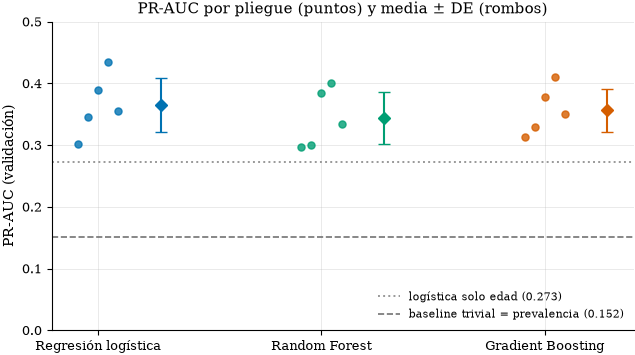

,Regresión logística,Random Forest,Gradient Boosting
pliegue 1,0.302,0.297,0.313
pliegue 2,0.345,0.300,0.329
pliegue 3,0.390,0.384,0.378
pliegue 4,0.434,0.400,0.411
pliegue 5,0.355,0.335,0.351


In [12]:
# PR-AUC de la mejor configuración de cada modelo, pliegue por pliegue
pliegues = pd.DataFrame({nombre: [gs.cv_results_[f"split{f}_test_pr_auc"][gs.best_index_] for f in range(N_FOLDS)]
                         for nombre, gs in busquedas.items()},
                        index=[f"pliegue {f + 1}" for f in range(N_FOLDS)])
print("modelo con mayor PR-AUC en cada pliegue:")
print(pliegues.idxmax(axis=1).value_counts().to_string())

fig, ax = plt.subplots(figsize=(6.4, 3.6))
for k, nombre in enumerate(pliegues.columns):
    v = pliegues[nombre].to_numpy()
    ax.scatter(np.full(N_FOLDS, k) + np.linspace(-0.09, 0.09, N_FOLDS), v, color=COLORES[nombre], s=26, zorder=3, alpha=0.8)
    ax.errorbar(k + 0.28, v.mean(), yerr=v.std(), fmt="D", color=COLORES[nombre], capsize=4, ms=6)
ax.axhline(baselines_cv.loc["Logística solo edad", "PR-AUC (CV)"], color="#999999", ls=":", lw=1.4,
           label=f"logística solo edad ({baselines_cv.loc['Logística solo edad', 'PR-AUC (CV)']:.3f})")
ax.axhline(y_train.mean(), color="0.45", ls="--", lw=1.2, label=f"baseline trivial = prevalencia ({y_train.mean():.3f})")
ax.set_xticks(range(len(pliegues.columns)))
ax.set_xticklabels(pliegues.columns)
ax.set_ylim(0, 0.5)
ax.set_ylabel("PR-AUC (validación)")
ax.set_title("PR-AUC por pliegue (puntos) y media ± DE (rombos)")
ax.legend(loc="lower right", fontsize=8)
guardar(fig, "11-cv-pr-auc-pliegues.png")
pliegues.round(4)

Los tres modelos **más que duplican la PR-AUC del baseline trivial** (0,343 a 0,365, frente a 0,152)
y superan con claridad a la logística solo con edad (0,273). La regresión logística obtiene los
valores más altos (PR-AUC 0,365 ± 0,044; ROC-AUC 0,731 ± 0,029), seguida por Gradient Boosting
(0,356 ± 0,035) y Random Forest (0,343 ± 0,042). Usar las 15 variables, en lugar de solo la edad,
aporta unos +0,09 de PR-AUC.

Sin embargo, las diferencias entre los tres modelos (como mucho 0,022 de PR-AUC) son **menores que
la variación entre pliegues** (desviación estándar entre 0,035 y 0,044). La figura lo muestra: los
tres coinciden en qué pliegues son difíciles (pliegue 1, PR-AUC ≈ 0,30) y cuáles fáciles (pliegue 4,
≈ 0,40–0,43). El desempeño depende más de qué personas caen en cada pliegue que del modelo elegido.
Pliegue a pliegue, la logística gana en 4 de 5 y Gradient Boosting en 1.

Los hiperparámetros elegidos también aportan información:

* **Los tres modelos eligieron `class_weight=None`**: ponderar la clase minoritaria no mejora la
  PR-AUC (sección 5.2).
* **Los modelos de árboles prefirieron configuraciones simples.** Random Forest eligió árboles poco
  profundos (`max_depth=6`). Gradient Boosting eligió la configuración más conservadora de su grilla:
  tasa de aprendizaje baja (0,03), el menor número de iteraciones (100) y de hojas (7), y hojas de al
  menos 50 personas. La validación cruzada penalizó la complejidad: hay poca estructura no lineal que
  aprovechar, coherente con las correlaciones individuales débiles del EDA (máximo 0,23).
* La logística eligió `C = 0,1`, una regularización moderada.

En costo computacional, la búsqueda tardó menos de 20 s en la logística y en Gradient Boosting, y
alrededor de un minuto y medio en Random Forest, con grillas de 22, 32 y 48 combinaciones,
respectivamente (los tiempos exactos dependen del equipo).

### 5.1 Efecto de la regularización en la regresión logística

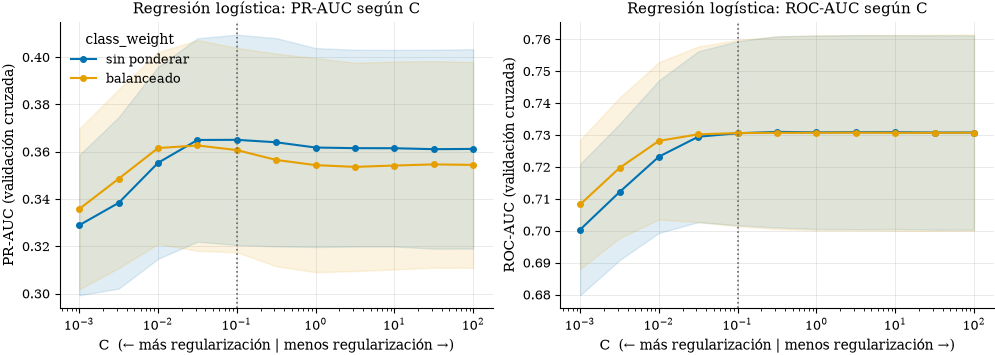

In [13]:
# Curva de validación de la regresión logística: efecto de C y de class_weight
res = pd.DataFrame(busquedas["Regresión logística"].cv_results_)
res["pesos"] = res["param_modelo__class_weight"].map(lambda v: "balanceado" if v == "balanced" else "sin ponderar")
res["C"] = res["param_modelo__C"].astype(float)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
for pesos, color in [("sin ponderar", "#0072B2"), ("balanceado", "#E69F00")]:
    d = res[res["pesos"] == pesos].sort_values("C")
    for a, m in zip(ax, ["pr_auc", "roc_auc"]):
        a.plot(d["C"], d[f"mean_test_{m}"], "o-", color=color, label=pesos, ms=4)
        a.fill_between(d["C"], d[f"mean_test_{m}"] - d[f"std_test_{m}"], d[f"mean_test_{m}"] + d[f"std_test_{m}"],
                       color=color, alpha=0.12)
C_best = busquedas["Regresión logística"].best_params_["modelo__C"]
for a, titulo in zip(ax, ["PR-AUC", "ROC-AUC"]):
    a.set_xscale("log")
    a.axvline(C_best, color="0.4", ls=":", lw=1.2)
    a.set_xlabel("C  (← más regularización | menos regularización →)")
    a.set_ylabel(f"{titulo} (validación cruzada)")
    a.set_title(f"Regresión logística: {titulo} según C")
ax[0].legend(title="class_weight")
guardar(fig, "12-curva-validacion-logistica.png")

La curva de validación muestra dos cosas:

* **Regularizar demasiado perjudica; regularizar poco no.** Con `C` ≤ 0,01 la PR-AUC cae (hasta
  ≈ 0,33 con `C` = 0,001), porque los coeficientes quedan tan encogidos que el modelo pierde señal.
  Desde `C` ≈ 0,03 la curva es prácticamente plana (0,361–0,365): con 16 variables y 3 392
  observaciones hay poco riesgo de sobreajuste, y el papel principal de la regularización L2 es
  estabilizar los coeficientes de las variables correlacionadas (`sysBP`, `diaBP`, `pulsePressure`,
  `prevalentHyp`).
* **Ponderar las clases no mejora el ranking.** Con `class_weight="balanced"` la mejor PR-AUC es
  ≈ 0,363 (en `C` ≈ 0,03), frente a 0,365 sin ponderar, y las curvas de ROC-AUC se superponen.

Las bandas sombreadas (± 1 desviación estándar, unas 0,04) cubren todas las diferencias entre
configuraciones razonables: el modelo es robusto a la elección exacta de `C`.

### 5.2 Manejo del desbalance de clases

Se compara, para la mejor configuración de cada modelo, entrenar **sin ponderar** las clases frente a
`class_weight="balanced"` (`"balanced_subsample"` en Random Forest). Además de la PR-AUC y la ROC-AUC,
se reporta la **probabilidad media predicha** en las predicciones *out-of-fold* (cada observación
predicha por un modelo que no la vio en entrenamiento). En un modelo bien calibrado, esa probabilidad
media debe parecerse a la prevalencia real (≈ 0,15).

In [14]:
filas = []
for nombre, gs in busquedas.items():
    peso = "balanced_subsample" if nombre == "Random Forest" else "balanced"
    for estrategia, cw in [("sin ponderar", None), ("class_weight balanceado", peso)]:
        est = clone(gs.best_estimator_).set_params(modelo__class_weight=cw)
        oof_p = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
        filas.append({"modelo": nombre, "estrategia": estrategia, **resumen_cv(est),
                      "prob. media predicha": oof_p.mean()})
desbalance = pd.DataFrame(filas).set_index(["modelo", "estrategia"])
desbalance.to_csv(TABLE_DIR / "p2-desbalance.csv")
print(f"prevalencia real en entrenamiento: {y_train.mean():.4f}")
desbalance.round(4)

prevalencia real en entrenamiento: 0.1518


PR-AUC (CV)   ± DE  ROC-AUC (CV)  \
modelo              estrategia                                                  
Regresión logística sin ponderar                   0.365  0.044         0.731   
                    class_weight balanceado        0.361  0.043         0.731   
Random Forest       sin ponderar                   0.343  0.042         0.724   
                    class_weight balanceado        0.323  0.042         0.712   
Gradient Boosting   sin ponderar                   0.356  0.035         0.723   
                    class_weight balanceado        0.343  0.038         0.722   

                                             prob. media predicha  
modelo              estrategia                                     
Regresión logística sin ponderar                            0.152  
                    class_weight balanceado                 0.441  
Random Forest       sin ponderar                            0.150  
                    class_weight balanceado                 0.388  
Gradient Boosting   sin ponderar                            0.153  
                    class_weight balanceado                 0.433

Ponderar la clase minoritaria **no mejora la discriminación en ningún modelo** y en dos de ellos la
empeora: la PR-AUC baja de 0,365 a 0,361 en la logística, de 0,356 a 0,342 en Gradient Boosting y de
0,343 a 0,323 en Random Forest. La ROC-AUC queda igual o baja.

El efecto más importante está en la última columna. Sin ponderar, la probabilidad media predicha
(0,150–0,153) coincide con la prevalencia real (0,152): el modelo está **calibrado**. Con
`class_weight="balanced"` sube a **0,39–0,44**, casi el triple. El modelo pasa a "creer" que la
enfermedad es mucho más frecuente de lo que es. Para un modelo cuyo producto es una estimación de
riesgo, eso es un problema serio: diría a una persona que tiene un 40 % de riesgo cuando el riesgo
real de alguien con su perfil es cercano al 15 %.

La conclusión es que el desbalance **no se resuelve modificando el entrenamiento, sino con el umbral
de decisión** (sección 7). El modelo se entrena sin ponderar, con probabilidades fieles, y el umbral
se fija bajo para detectar la mayoría de los casos positivos.

Este resultado es el que respalda haber descartado SMOTE (sección 4.3): el problema no está en una
técnica concreta de reequilibrio, sino en reequilibrar, porque cualquier método que le muestre al modelo
una prevalencia artificial le enseña una probabilidad base falsa [5]. Para un modelo de riesgo, la
calibración es tan importante como la discriminación [7].


## 6. Selección del modelo (solo con validación cruzada)

La regla se fijó antes de ver resultados: **gana el modelo con mayor PR-AUC media en validación
cruzada**. El conjunto de prueba no interviene en esta decisión; si lo hiciera, la métrica de prueba
dejaría de ser una estimación honesta (elegir el mejor de varios sobre los mismos datos infla su
desempeño aparente). La misma regla decide qué modelo de árboles representa a los no lineales en el
resto del análisis.

In [15]:
modelos = ["Regresión logística", "Random Forest", "Gradient Boosting"]
modelo_final = max(modelos, key=lambda n: tabla_cv.loc[n, "PR-AUC (CV)"])
no_lineal = max(["Random Forest", "Gradient Boosting"], key=lambda n: tabla_cv.loc[n, "PR-AUC (CV)"])

dif = tabla_cv.loc["Gradient Boosting", "PR-AUC (CV)"] - tabla_cv.loc["Random Forest", "PR-AUC (CV)"]
print(f"modelo final (mayor PR-AUC en CV): {modelo_final}")
print(f"mejor modelo no lineal:            {no_lineal}")
print(f"diferencia de PR-AUC (Boosting - Random Forest) en CV: {dif:+.4f}")

modelo final (mayor PR-AUC en CV): Regresión logística
mejor modelo no lineal:            Gradient Boosting
diferencia de PR-AUC (Boosting - Random Forest) en CV: +0.0129


### 6.1 ¿Cambia algo imputar por sexo?

Se compara la imputación por sexo de `glucose`, `totChol` y `BMI` contra la alternativa más simple
(mediana global), con el mismo modelo y la misma validación cruzada.

In [16]:
# misma logística elegida en la sección 5 (C = 0,1); solo cambia la estrategia de imputación
lr_mejor = busquedas["Regresión logística"].best_estimator_
pd.DataFrame({etiqueta: resumen_cv(clone(lr_mejor).set_params(preproc=build_preprocessor(imputar_por_sexo=por_sexo)))
              for etiqueta, por_sexo in [("mediana global", False), ("mediana por sexo", True)]}).T.round(4)

,PR-AUC (CV),± DE,ROC-AUC (CV)
mediana global,0.366,0.044,0.731
mediana por sexo,0.365,0.044,0.731


Las dos estrategias dan el mismo resultado: PR-AUC 0,3650 imputando por sexo frente a 0,3656 con la
mediana global. La diferencia (0,0006) favorece levemente a la mediana global, pero es unas 70 veces
menor que la variación entre pliegues (0,044), así que no es distinguible del azar. La razón está en las
medianas aprendidas: la de **glucosa es 78 mg/dL en ambos sexos**, así que imputar por sexo o
globalmente da el mismo valor. En `totChol` (237 frente a 230 mg/dL) y `BMI` (24,8 frente a 26,0 kg/m²)
las medianas sí difieren, pero esas variables tienen muy pocos faltantes (1,2 % y 0,5 %) y su efecto en
el modelo es pequeño.

Se conserva la imputación por sexo porque es la decisión coherente con el EDA (el faltante de `glucose`
se asocia al sexo) y no tiene costo, pero se reporta que su efecto en el desempeño es nulo. La
estrategia de imputación no es un factor relevante en este problema; la sección 6.3 lo confirma por
otra vía.


### 6.2 ¿Aporta la presión de pulso?

Se re-evalúa cada modelo, con sus mejores hiperparámetros, quitando `pulsePressure` del
preprocesamiento.

In [17]:
filas = []
for nombre, gs in busquedas.items():
    for etiqueta, con_pulso in [("con pulsePressure", True), ("sin pulsePressure", False)]:
        est = clone(gs.best_estimator_).set_params(preproc=build_preprocessor(pulse_pressure=con_pulso))
        filas.append({"modelo": nombre, "variables": etiqueta, **resumen_cv(est)})
pulso_ablacion = pd.DataFrame(filas).set_index(["modelo", "variables"])
pulso_ablacion.to_csv(TABLE_DIR / "p2-pulso-ablacion.csv")
pulso_ablacion.round(4)

PR-AUC (CV)   ± DE  ROC-AUC (CV)
modelo              variables                                          
Regresión logística con pulsePressure        0.365  0.044         0.731
                    sin pulsePressure        0.364  0.044         0.731
Random Forest       con pulsePressure        0.343  0.042         0.724
                    sin pulsePressure        0.344  0.040         0.725
Gradient Boosting   con pulsePressure        0.356  0.035         0.723
                    sin pulsePressure        0.349  0.040         0.718

El aporte de la presión de pulso confirma lo anticipado en la sección 3.2:

* En la **regresión logística** no cambia nada (PR-AUC 0,3650 con la variable frente a 0,3642 sin
  ella): al ser una resta de dos variables que el modelo ya tiene, no le agrega información.
* En **Random Forest** tampoco (0,3434 frente a 0,3444).
* En **Gradient Boosting** sube levemente (0,3563 frente a 0,3493, +0,007): los árboles se benefician
  de recibir la resta ya calculada. La mejora es una quinta parte de la desviación entre pliegues
  (0,035), de modo que es compatible con el ruido.

Se conserva la variable: no perjudica a ningún modelo, puede ayudar a los de árboles y tiene
interpretación clínica (rigidez arterial). Pero no es una fuente importante de desempeño.

### 6.3 Gradient Boosting sin imputar

`HistGradientBoostingClassifier` acepta valores faltantes de forma nativa: en cada división aprende
hacia qué rama enviar los `NaN`. Se compara, con la misma configuración, el modelo entrenado con el
*pipeline* de imputación contra el modelo entrenado sobre los datos con faltantes (solo se agrega la
presión de pulso, que no tiene faltantes).

In [18]:
mejores_hgb = {k.replace("modelo__", ""): v for k, v in busquedas["Gradient Boosting"].best_params_.items()}
hgb_nativo = Pipeline([("pulso", AnadirPresionPulso()),
                       ("modelo", HistGradientBoostingClassifier(random_state=SEED, **mejores_hgb))])
pd.DataFrame({"con imputación (pipeline)": resumen_cv(busquedas["Gradient Boosting"].best_estimator_),
              "NaN nativos, sin imputar": resumen_cv(hgb_nativo)}).T.round(4)

,PR-AUC (CV),± DE,ROC-AUC (CV)
con imputación (pipeline),0.356,0.035,0.723
"NaN nativos, sin imputar",0.355,0.036,0.724


Entrenar Gradient Boosting directamente sobre los datos con faltantes da una PR-AUC de 0,355 ± 0,036,
frente a 0,356 ± 0,035 con imputación: la misma cifra. Es coherente con la sección 6.1: en este
conjunto el patrón de faltantes aporta poca información, así que imputar por sexo, imputar con la
mediana global o dejar que el modelo maneje los `NaN` produce el mismo resultado.

### 6.4 Random Forest frente a Gradient Boosting

| | Random Forest | Gradient Boosting |
| --- | --- | --- |
| PR-AUC (CV) | 0,343 ± 0,042 | 0,356 ± 0,035 |
| ROC-AUC (CV) | 0,724 ± 0,032 | 0,723 ± 0,034 |
| Pliegues ganados (entre los tres modelos) | 0 de 5 | 1 de 5 |
| Configuración elegida | 300 árboles, profundidad 6 | 100 iteraciones, 7 hojas, hojas ≥ 50, tasa 0,03 |
| Tiempo de búsqueda | ≈ 90 s | < 20 s |
| Presión de pulso | sin efecto | +0,007 de PR-AUC |
| Valores faltantes | requiere imputación | nativo (sin ganancia en este conjunto) |

Por la regla fijada de antemano, Gradient Boosting representa a los modelos de árboles (PR-AUC
+0,013). Pero esa diferencia es un tercio de la desviación estándar entre pliegues, y en ROC-AUC
están empatados. **En la práctica son equivalentes en este problema**; la sección 8 lo confirma en
el conjunto de prueba. Las diferencias reales son operativas: Gradient Boosting es varias veces más
rápido de ajustar y no necesita imputación. Ninguno supera a la regresión logística.

## 7. Elección del umbral de decisión

Los modelos devuelven una probabilidad; para convertirla en una decisión ("derivar a evaluación" o
no) hace falta un umbral. El valor por defecto, 0,5, no tiene sentido aquí: con una prevalencia del
15 %, casi ninguna persona supera esa probabilidad y el modelo apenas detectaría casos.

El umbral se elige con las **predicciones *out-of-fold*** del conjunto de entrenamiento,
maximizando **F2**, una media armónica de precisión y recall que pondera el recall el doble. Esta
elección refleja el objetivo de tamizaje: un falso negativo (no detectar a alguien en riesgo) es más
costoso que un falso positivo (derivar a una persona sana a una evaluación adicional).

In [19]:
def umbral_f2(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f2 = 5 * prec * rec / np.maximum(4 * prec + rec, 1e-12)
    j = np.argmax(f2[:-1])
    return thr[j], prec[j], rec[j], f2[j]


candidatos = {**{n: gs.best_estimator_ for n, gs in busquedas.items()}, "Logística solo edad": baseline_age}
oof, umbrales, filas = {}, {}, []
for nombre, est in candidatos.items():
    oof[nombre] = cross_val_predict(est, X_train, y_train, cv=cv, method="predict_proba")[:, 1]
    t, p_, r_, f2 = umbral_f2(y_train, oof[nombre])
    umbrales[nombre] = t
    filas.append({"modelo": nombre, "umbral (máx. F2)": t, "precision": p_, "recall": r_, "F2": f2,
                  "% marcados como riesgo": 100 * (oof[nombre] >= t).mean()})
pd.DataFrame(filas).set_index("modelo").round(3)

,umbral (máx. F2),precision,recall,F2,% marcados como riesgo
modelo,,,,,
Regresión logística,0.102,0.220,0.841,0.537,58.019
Random Forest,0.115,0.225,0.819,0.536,55.307
Gradient Boosting,0.113,0.225,0.806,0.532,54.304
Logística solo edad,0.107,0.212,0.833,0.526,59.581


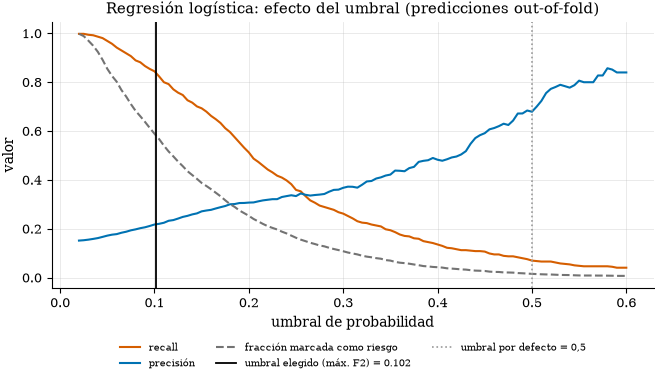

,recall,precisión,% marcados como riesgo
umbral,,,
0.050,0.969,0.172,85.495
0.102,0.841,0.220,58.019
0.150,0.693,0.271,38.768
0.200,0.513,0.307,25.324
0.300,0.262,0.368,10.820
0.500,0.070,0.679,1.562


In [20]:
# Curvas de precisión, recall y fracción marcada según el umbral (modelo final, predicciones out-of-fold)
p_oof = oof[modelo_final]
grid_t = np.linspace(0.02, 0.6, 117)
prec_t = [precision_score(y_train, p_oof >= t, zero_division=0) for t in grid_t]
rec_t = [recall_score(y_train, p_oof >= t) for t in grid_t]
frac_t = [(p_oof >= t).mean() for t in grid_t]

fig, ax = plt.subplots(figsize=(6.6, 3.8))
ax.plot(grid_t, rec_t, color="#D55E00", label="recall")
ax.plot(grid_t, prec_t, color="#0072B2", label="precisión")
ax.plot(grid_t, frac_t, color="0.45", ls="--", label="fracción marcada como riesgo")
ax.axvline(umbrales[modelo_final], color="black", lw=1.3, label=f"umbral elegido (máx. F2) = {umbrales[modelo_final]:.3f}")
ax.axvline(0.5, color="0.6", ls=":", lw=1.2, label="umbral por defecto = 0,5")
ax.set_xlabel("umbral de probabilidad")
ax.set_ylabel("valor")
ax.set_title(f"{modelo_final}: efecto del umbral (predicciones out-of-fold)")
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
guardar(fig, "13-umbral-decision.png")

# costo de cada umbral posible: qué se gana y qué se pierde
pd.DataFrame(
    [{"umbral": t, "recall": recall_score(y_train, p_oof >= t),
      "precisión": precision_score(y_train, p_oof >= t, zero_division=0),
      "% marcados como riesgo": 100 * (p_oof >= t).mean()}
     for t in [0.05, umbrales[modelo_final], 0.15, 0.20, 0.30, 0.50]]
).set_index("umbral").round(3)

Con el umbral por defecto (0,5), la regresión logística detectaría solo el **7 %** de los eventos y
marcaría al 1,6 % de las personas: inútil para tamizaje. Maximizando F2 sobre las predicciones
*out-of-fold*, los umbrales elegidos quedan todos alrededor de 0,10–0,12: 0,102 (logística), 0,115
(Random Forest), 0,113 (Gradient Boosting) y 0,107 (logística solo con edad).

Para la logística, el umbral de **0,102** significa, en términos clínicos, "derivar a evaluación a
toda persona con un riesgo estimado a 10 años de alrededor del 10 % o más". Con ese umbral se
detecta el 84,1 % de los eventos (en validación cruzada), con una precisión de 0,22, a cambio de
marcar al 58,0 % de las personas. La precisión de 0,22 supone que 1 de cada 4,5 personas marcadas
desarrolla el evento, frente a 1 de cada 6,6 en la población general.

La tabla resume el costo de cada alternativa. Bajar el umbral a 0,05 detecta el 96,9 % de los
eventos, pero marca al 85,5 % de la población (casi no filtra). Subirlo a 0,20 reduce la carga al
25,3 % de las personas, pero pierde la mitad de los eventos (recall 0,513). **El umbral es una
decisión de política sanitaria, no un resultado del modelo**: depende de cuántas evaluaciones
adicionales pueda absorber el sistema y de cuánto se valore no perder un caso. F2 es un criterio
explícito y reproducible para fijarlo, pero no el único razonable.

**Una advertencia metodológica.** Las predicciones *out-of-fold* provienen de los mismos pliegues con los
que se eligieron los hiperparámetros, así que son levemente optimistas: la configuración elegida es,
entre las probadas, la que mejor resultado obtuvo en esos pliegues. Lo riguroso sería una validación
cruzada anidada (un bucle interno para los hiperparámetros y otro externo para evaluar). Con curvas de
validación tan planas como la de la sección 5.1, el sesgo esperado es pequeño, y el conjunto de prueba
(sección 8) permite comprobar si el umbral se sostiene en datos nuevos.


## 8. Evaluación final en el conjunto de prueba

Esta es la única vez que se usa el 20 % de prueba. Cada modelo usa los hiperparámetros y el umbral
elegidos por validación cruzada; `GridSearchCV` ya re-entrenó la mejor configuración sobre el 100 %
del conjunto de entrenamiento.

In [21]:
finales = {n: busquedas[n].best_estimator_ for n in modelos}
finales["Logística solo edad"] = clone(baseline_age).fit(X_train, y_train)
trivial = clone(baseline_trivial).fit(X_train, y_train)

evaluados = ["Logística solo edad"] + modelos
proba = {n: finales[n].predict_proba(X_test)[:, 1] for n in evaluados}
proba_trivial = trivial.predict_proba(X_test)[:, 1]


def metricas(y_true, p, t):
    pred = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"umbral": t, "accuracy": accuracy_score(y_true, pred),
            "precision": precision_score(y_true, pred, zero_division=0), "recall": recall_score(y_true, pred),
            "F1": f1_score(y_true, pred, zero_division=0), "F2": fbeta_score(y_true, pred, beta=2, zero_division=0),
            "ROC-AUC": roc_auc_score(y_true, p), "PR-AUC": average_precision_score(y_true, p),
            "Brier": brier_score_loss(y_true, p), "% marcados": 100 * pred.mean(),
            "TP": tp, "FP": fp, "FN": fn, "TN": tn}


filas = [{"modelo": "Baseline trivial", **metricas(y_test, proba_trivial, 0.5)}]
filas += [{"modelo": n, **metricas(y_test, proba[n], umbrales[n])} for n in evaluados]
tabla_test = pd.DataFrame(filas).set_index("modelo")
tabla_test.to_csv(TABLE_DIR / "p2-test-metricas.csv")
tabla_test.round(3)

,umbral,accuracy,precision,recall,F1,F2,ROC-AUC,PR-AUC,Brier,% marcados,TP,FP,FN,TN
modelo,,,,,,,,,,,,,,
Baseline trivial,0.500,0.848,0.000,0.000,0.000,0.000,0.500,0.152,0.129,0.000,0,0,129,719
Logística solo edad,0.107,0.509,0.202,0.752,0.318,0.486,0.638,0.227,0.126,56.722,97,384,32,335
Regresión logística,0.102,0.541,0.221,0.798,0.346,0.524,0.702,0.302,0.121,54.953,103,363,26,356
Random Forest,0.115,0.535,0.209,0.736,0.325,0.489,0.680,0.275,0.122,53.656,95,360,34,359
Gradient Boosting,0.113,0.535,0.206,0.721,0.321,0.481,0.670,0.275,0.123,53.184,93,358,36,361


### 8.1 Incertidumbre: intervalos de confianza por *bootstrap*

El conjunto de prueba tiene 848 personas y solo 129 eventos, así que cada métrica tiene una
incertidumbre considerable. Se remuestrea el conjunto de prueba 2 000 veces con reemplazo [8] (los
mismos remuestreos para todos los modelos, lo que permite comparar diferencias pareadas) y se reporta
el intervalo percentil del 95 %.

In [22]:
rng = np.random.default_rng(SEED)
B = 2000
yt = y_test.to_numpy()
remuestras = [rng.integers(0, len(yt), len(yt)) for _ in range(B)]

boot = {}
for n in evaluados:
    p, t = proba[n], umbrales[n]
    pred = (p >= t).astype(int)
    boot[n] = pd.DataFrame({
        "ROC-AUC": [roc_auc_score(yt[ix], p[ix]) for ix in remuestras],
        "PR-AUC": [average_precision_score(yt[ix], p[ix]) for ix in remuestras],
        "recall": [recall_score(yt[ix], pred[ix]) for ix in remuestras],
        "precision": [precision_score(yt[ix], pred[ix], zero_division=0) for ix in remuestras],
    })

filas = []
for n in evaluados:
    for m in ["ROC-AUC", "PR-AUC", "recall", "precision"]:
        lo, hi = np.percentile(boot[n][m], [2.5, 97.5])
        filas.append({"modelo": n, "métrica": m, "estimación": tabla_test.loc[n, m], "IC 95 % inf.": lo, "IC 95 % sup.": hi})
ic = pd.DataFrame(filas).set_index(["modelo", "métrica"])
ic.to_csv(TABLE_DIR / "p2-test-intervalos.csv")
ic.round(3)

estimación  IC 95 % inf.  IC 95 % sup.
modelo              métrica                                          
Logística solo edad ROC-AUC         0.638         0.585         0.690
                    PR-AUC          0.227         0.183         0.292
                    recall          0.752         0.675         0.826
                    precision       0.202         0.165         0.240
Regresión logística ROC-AUC         0.702         0.653         0.746
                    PR-AUC          0.302         0.237         0.380
                    recall          0.798         0.727         0.867
                    precision       0.221         0.183         0.260
Random Forest       ROC-AUC         0.680         0.630         0.729
                    PR-AUC          0.275         0.220         0.351
                    recall          0.736         0.659         0.811
                    precision       0.209         0.172         0.249
Gradient Boosting   ROC-AUC         0.670         0.618         0.720
                    PR-AUC          0.275         0.217         0.357
                    recall          0.721         0.642         0.800
                    precision       0.206         0.168         0.245

In [23]:
# Diferencias pareadas entre modelos sobre los mismos remuestreos
filas = []
for a, b in [("Regresión logística", "Logística solo edad"), ("Regresión logística", "Random Forest"),
             ("Regresión logística", "Gradient Boosting"), ("Gradient Boosting", "Random Forest")]:
    for m in ["ROC-AUC", "PR-AUC"]:
        d = boot[a][m] - boot[b][m]
        lo, hi = np.percentile(d, [2.5, 97.5])
        filas.append({"comparación": f"{a} − {b}", "métrica": m, "diferencia": tabla_test.loc[a, m] - tabla_test.loc[b, m],
                      "IC 95 % inf.": lo, "IC 95 % sup.": hi, "% remuestreos con diferencia > 0": 100 * (d > 0).mean()})
dif_pareadas = pd.DataFrame(filas).set_index(["comparación", "métrica"])
dif_pareadas.to_csv(TABLE_DIR / "p2-test-diferencias.csv")
dif_pareadas.round(3)

diferencia  IC 95 % inf.  \
comparación                               métrica                             
Regresión logística − Logística solo edad ROC-AUC       0.064         0.027   
                                          PR-AUC        0.074         0.022   
Regresión logística − Random Forest       ROC-AUC       0.021         0.001   
                                          PR-AUC        0.027        -0.006   
Regresión logística − Gradient Boosting   ROC-AUC       0.032         0.010   
                                          PR-AUC        0.027        -0.011   
Gradient Boosting − Random Forest         ROC-AUC      -0.011        -0.031   
                                          PR-AUC       -0.000        -0.023   

                                                   IC 95 % sup.  \
comparación                               métrica                 
Regresión logística − Logística solo edad ROC-AUC         0.097   
                                          PR-AUC          0.128   
Regresión logística − Random Forest       ROC-AUC         0.042   
                                          PR-AUC          0.057   
Regresión logística − Gradient Boosting   ROC-AUC         0.053   
                                          PR-AUC          0.059   
Gradient Boosting − Random Forest         ROC-AUC         0.009   
                                          PR-AUC          0.028   

                                                   % remuestreos con diferencia > 0  
comparación                               métrica                                    
Regresión logística − Logística solo edad ROC-AUC                            100.00  
                                          PR-AUC                              99.60  
Regresión logística − Random Forest       ROC-AUC                             97.75  
                                          PR-AUC                              94.30  
Regresión logística − Gradient Boosting   ROC-AUC                             99.80  
                                          PR-AUC                              89.75  
Gradient Boosting − Random Forest         ROC-AUC                             16.30  
                                          PR-AUC                              51.10

**Discriminación.** En el conjunto de prueba, la regresión logística vuelve a quedar primera:
PR-AUC **0,302** [IC 95 %: 0,237–0,380] y ROC-AUC **0,702** [0,653–0,746]. Le siguen Random Forest
(0,275 y 0,680), Gradient Boosting (0,275 y 0,670), la logística solo con edad (0,227 y 0,638) y el
baseline trivial (0,152 y 0,5).

Los valores de prueba son algo menores que las medias de validación cruzada (0,365 y 0,731), pero
están dentro de la variación observada entre pliegues (PR-AUC de 0,30 a 0,43) y dentro de los
intervalos de confianza. La ROC-AUC de 0,702 se ubica en el extremo inferior del rango de 0,70–0,78
que reporta la literatura para modelos de riesgo de tipo Framingham en validaciones externas [9].

**Comparación pareada** (la diferencia se calcula en cada uno de los 2 000 remuestreos):

* **Las 15 variables frente a solo la edad:** +0,064 de ROC-AUC [0,027; 0,097] y +0,074 de PR-AUC
  [0,022; 0,128]. Ambos intervalos excluyen el cero: el resto de las variables aporta información
  real.
* **Logística frente a los modelos de árboles:** en **ROC-AUC** la ventaja es estadísticamente clara
  frente a Gradient Boosting (+0,032 [0,010; 0,053]) y marginal frente a Random Forest
  (+0,021 [0,001; 0,042]). En **PR-AUC** la logística también va adelante (+0,027 en ambos casos),
  pero los intervalos incluyen el cero (gana en el 94 % y el 90 % de los remuestreos).
* **Random Forest frente a Gradient Boosting:** empate. La PR-AUC es idéntica (diferencia −0,000
  [−0,023; 0,028], cada uno gana en la mitad de los remuestreos) y la ROC-AUC difiere en −0,011
  [−0,031; 0,009].

**Con el umbral elegido**, la logística detecta **103 de los 129 eventos** (recall 0,798
[0,727–0,867]) con una precisión de 0,221, y marca al 55,0 % de las personas. Su exactitud (0,541)
es menor que la del baseline trivial (0,848). Es lo esperado, y lo correcto: el modelo cambia
aciertos fáciles en la clase mayoritaria por la detección de casos reales, que es el objetivo del
tamizaje.

**¿Se sostiene el umbral?** En prueba, el umbral de 0,102 detecta el 79,8 % de los eventos y marca al
55,0 % de las personas, frente al 84,1 % y el 58,0 % estimados en validación cruzada (sección 7). La
caída del recall (unos 4 puntos) es compatible con el leve optimismo advertido en la sección 7 y queda
dentro del intervalo de confianza [0,727; 0,867].


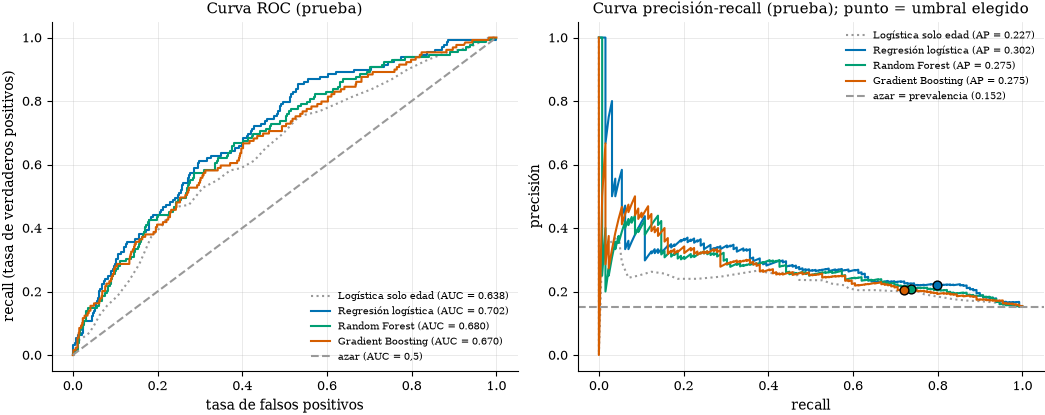

In [24]:
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.2))
for n in evaluados:
    estilo = ":" if n == "Logística solo edad" else "-"
    fpr, tpr, _ = roc_curve(y_test, proba[n])
    ax[0].plot(fpr, tpr, estilo, color=COLORES[n], label=f"{n} (AUC = {tabla_test.loc[n, 'ROC-AUC']:.3f})")
    prec, rec, _ = precision_recall_curve(y_test, proba[n])
    ax[1].plot(rec, prec, estilo, color=COLORES[n], label=f"{n} (AP = {tabla_test.loc[n, 'PR-AUC']:.3f})")
    if n != "Logística solo edad":
        ax[1].scatter(tabla_test.loc[n, "recall"], tabla_test.loc[n, "precision"], color=COLORES[n], s=40,
                      zorder=4, edgecolor="black")
ax[0].plot([0, 1], [0, 1], "--", color="0.6", label="azar (AUC = 0,5)")
ax[1].axhline(y_test.mean(), ls="--", color="0.6", label=f"azar = prevalencia ({y_test.mean():.3f})")
ax[0].set_xlabel("tasa de falsos positivos"); ax[0].set_ylabel("recall (tasa de verdaderos positivos)")
ax[0].set_title("Curva ROC (prueba)")
ax[1].set_xlabel("recall"); ax[1].set_ylabel("precisión")
ax[1].set_title("Curva precisión-recall (prueba); punto = umbral elegido")
ax[0].legend(fontsize=7, loc="lower right")
ax[1].legend(fontsize=7, loc="upper right")
guardar(fig, "14-roc-pr-test.png")

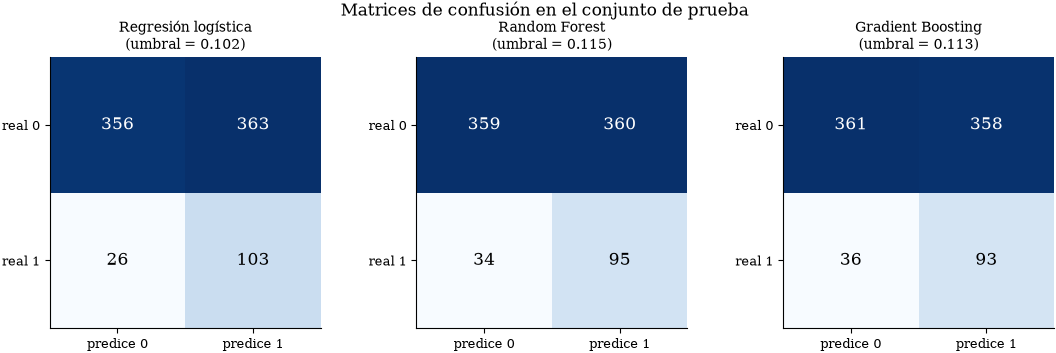

In [25]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for a, n in zip(axes, modelos):
    cm = confusion_matrix(y_test, (proba[n] >= umbrales[n]).astype(int))
    a.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=12,
                   color="white" if cm[i, j] > cm.max() / 2 else "black")
    a.set_xticks([0, 1]); a.set_xticklabels(["predice 0", "predice 1"])
    a.set_yticks([0, 1]); a.set_yticklabels(["real 0", "real 1"])
    a.set_title(f"{n}\n(umbral = {umbrales[n]:.3f})", fontsize=10)
    a.grid(False)
fig.suptitle("Matrices de confusión en el conjunto de prueba", y=1.04)
guardar(fig, "15-matrices-confusion.png")

Como los tres modelos terminaron con umbrales parecidos (0,10–0,12) y marcan una fracción similar de
la población (53–55 %), sus matrices se pueden comparar casi directamente:

* **Regresión logística:** 103 verdaderos positivos, 26 falsos negativos y 363 falsos positivos.
* **Random Forest:** 95 verdaderos positivos, 34 falsos negativos y 360 falsos positivos.
* **Gradient Boosting:** 93 verdaderos positivos, 36 falsos negativos y 358 falsos positivos.

**Con prácticamente la misma cantidad de falsas alarmas, la logística detecta entre 8 y 10 eventos
más.** Por eso obtiene el mejor F2 en prueba (0,524, frente a 0,489 y 0,481). En los tres modelos
hacen falta entre 3,5 y 3,9 falsos positivos por cada evento detectado. Ese es el techo de precisión
que imponen 15 factores de riesgo con correlaciones individuales bajas, no una deficiencia de un
modelo en particular.

### 8.2 Calibración

Como el objetivo es estimar un **riesgo**, importa que las probabilidades sean fieles: entre las
personas a las que el modelo asigna un 20 % de riesgo, alrededor del 20 % debería desarrollar el
evento. La curva de calibración agrupa las predicciones en quintiles y compara la probabilidad media
predicha con la frecuencia observada. El *Brier score* (error cuadrático medio de la probabilidad)
resume a la vez calibración y discriminación; menor es mejor.

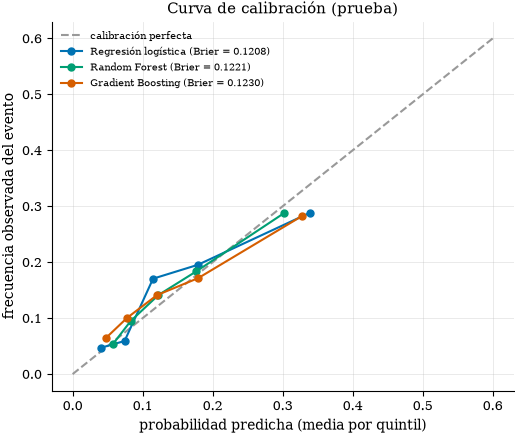

prevalencia en prueba: 0.1521
probabilidad media predicha, Regresión logística : 0.1494
probabilidad media predicha, Random Forest       : 0.1483
probabilidad media predicha, Gradient Boosting   : 0.1506
Brier del baseline trivial (asignar a todos la prevalencia): 0.1290


In [26]:
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.plot([0, 0.6], [0, 0.6], "--", color="0.6", label="calibración perfecta")
for n in modelos:
    obs, pred_m = calibration_curve(y_test, proba[n], n_bins=5, strategy="quantile")
    ax.plot(pred_m, obs, "o-", color=COLORES[n], label=f"{n} (Brier = {tabla_test.loc[n, 'Brier']:.4f})")
ax.set_xlabel("probabilidad predicha (media por quintil)")
ax.set_ylabel("frecuencia observada del evento")
ax.set_title("Curva de calibración (prueba)")
ax.legend(fontsize=7.5)
guardar(fig, "16-calibracion.png")

print(f"prevalencia en prueba: {y_test.mean():.4f}")
for n in modelos:
    print(f"probabilidad media predicha, {n:20s}: {proba[n].mean():.4f}")
print(f"Brier del baseline trivial (asignar a todos la prevalencia): {tabla_test.loc['Baseline trivial', 'Brier']:.4f}")

Los tres modelos están **calibrados en promedio**: la probabilidad media predicha (0,148–0,151)
coincide con la prevalencia observada en prueba (0,152). Esto es consecuencia directa de haber
entrenado sin ponderar las clases (sección 5.2).

Por quintiles, los tres modelos siguen de cerca la diagonal. En el quintil de mayor riesgo, la
logística y Gradient Boosting sobreestiman levemente (predicen ≈ 0,33–0,34 y se observa ≈ 0,28–0,29),
mientras que Random Forest queda casi sobre la diagonal. El *Brier score* favorece a la logística
(0,1208), seguida por Random Forest (0,1221) y Gradient Boosting (0,1230).

La referencia es el baseline trivial, que asigna a todos la prevalencia (Brier 0,1290). Frente a él,
la logística mejora el error probabilístico en torno a un 6 %: una ganancia modesta, coherente con
su discriminación moderada. A cambio, sus probabilidades **pueden leerse directamente como riesgo
estimado a 10 años**, que es el producto que busca el proyecto.

## 9. Interpretación del modelo

### 9.1 Coeficientes de la regresión logística: razones de *odds*

En una regresión logística, $\exp(\beta_j)$ es la **razón de *odds*** (OR) asociada a la variable
$j$: cuánto se multiplican las *odds* del evento cuando la variable aumenta una unidad, manteniendo
fijas las demás. Como las numéricas pasaron por `RobustScaler`, su "unidad" es **un rango
intercuartílico (IQR)** de la variable, calculado en el conjunto de entrenamiento; para las binarias
la unidad es pasar de 0 a 1 (presencia frente a ausencia), y para `education`, un nivel educativo.

In [27]:
lr = finales["Regresión logística"]
escalar = lr.named_steps["preproc"].named_steps["escalar"]
nombres = escalar.get_feature_names_out()
coef = lr.named_steps["modelo"].coef_[0]

# IQR (escala del RobustScaler) de cada variable numérica, para expresar la unidad del OR
iqr = dict(zip(escalar.transformers_[0][2], escalar.named_transformers_["num"].scale_))
UNIDAD = {"age": "años", "totChol": "mg/dL", "sysBP": "mm Hg", "diaBP": "mm Hg", "BMI": "kg/m²",
          "heartRate": "lpm", "glucose": "mg/dL", "cigsPerDay": "cig/día", "pulsePressure": "mm Hg"}


def unidad(v):
    if v in iqr:
        return f"+1 IQR ({iqr[v]:.1f} {UNIDAD[v]})"
    return "+1 nivel" if v == "education" else "presencia (0 → 1)"


odds = pd.DataFrame({"variable": nombres, "coeficiente": coef, "OR": np.exp(coef),
                     "unidad del OR": [unidad(v) for v in nombres]}).set_index("variable")
odds = odds.sort_values("OR", ascending=False)
odds.to_csv(TABLE_DIR / "p2-odds-ratios.csv")
odds.round(3)

,coeficiente,OR,unidad del OR
variable,,,
age,0.869,2.385,+1 IQR (14.0 años)
male,0.415,1.515,presencia (0 → 1)
cigsPerDay,0.389,1.475,+1 IQR (20.0 cig/día)
prevalentStroke,0.369,1.447,presencia (0 → 1)
BPMeds,0.275,1.316,presencia (0 → 1)
prevalentHyp,0.161,1.175,presencia (0 → 1)
sysBP,0.155,1.168,+1 IQR (27.0 mm Hg)
diaBP,0.144,1.155,+1 IQR (15.0 mm Hg)
pulsePressure,0.144,1.154,+1 IQR (16.0 mm Hg)


In [28]:
# sysBP, diaBP y pulsePressure son linealmente dependientes (pulsePressure = sysBP - diaBP):
# sus coeficientes no se interpretan por separado, solo su efecto conjunto.
b = dict(zip(nombres, coef))
por_mmHg = {v: b[v] / iqr[v] for v in ["sysBP", "diaBP", "pulsePressure"]}   # coeficiente por mm Hg
ef_sist = por_mmHg["sysBP"] + por_mmHg["pulsePressure"]       # +1 sistólica: también sube la de pulso
ef_diast = por_mmHg["diaBP"] - por_mmHg["pulsePressure"]      # +1 diastólica: baja la de pulso
print(f"+10 mm Hg de sistólica (diastólica fija): OR = {np.exp(10 * ef_sist):.3f}")
print(f"+10 mm Hg de diastólica (sistólica fija): OR = {np.exp(10 * ef_diast):.3f}")
print(f"+10 mm Hg en ambas (pulso fijo):         OR = {np.exp(10 * (por_mmHg['sysBP'] + por_mmHg['diaBP'])):.3f}")

+10 mm Hg de sistólica (diastólica fija): OR = 1.159
+10 mm Hg de diastólica (sistólica fija): OR = 1.006
+10 mm Hg en ambas (pulso fijo):         OR = 1.166


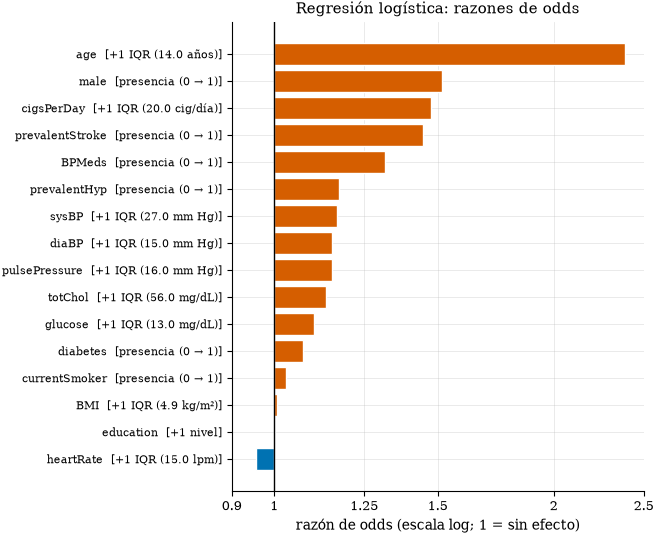

In [29]:
o = odds.sort_values("OR")
fig, ax = plt.subplots(figsize=(6.6, 5.4))
colores_or = ["#D55E00" if v > 1 else "#0072B2" for v in o["OR"]]
ax.barh([f"{v}  [{u}]" for v, u in zip(o.index, o["unidad del OR"])], o["OR"] - 1, left=1, color=colores_or, edgecolor="white")
ax.axvline(1, color="black", lw=1)
ax.set_xscale("log")
ax.set_xticks([0.9, 1, 1.25, 1.5, 2, 2.5])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.FormatStrFormatter("%g"))
ax.xaxis.set_minor_formatter(plt.matplotlib.ticker.NullFormatter())
ax.set_xlabel("razón de odds (escala log; 1 = sin efecto)")
ax.set_title("Regresión logística: razones de odds")
ax.tick_params(axis="y", labelsize=8)
guardar(fig, "17-odds-ratios.png")

In [30]:
# Estabilidad de las OR frente a la regularización: se re-entrena la logística con distintos C
filas = []
for C_ in [0.03, 0.1, 0.3, 1, 10]:
    m = clone(lr).set_params(modelo__C=C_).fit(X_train, y_train)
    o = dict(zip(nombres, np.exp(m.named_steps["modelo"].coef_[0])))
    filas.append({"C": C_, **{v: o[v] for v in ["age", "male", "cigsPerDay", "prevalentStroke", "BPMeds"]}})
print(f"prevalentStroke en entrenamiento: {int(X_train['prevalentStroke'].sum())} casos, "
      f"{int(y_train[X_train['prevalentStroke'] == 1].sum())} con evento")
pd.DataFrame(filas).set_index("C").round(3)

prevalentStroke en entrenamiento: 22 casos, 11 con evento


,age,male,cigsPerDay,prevalentStroke,BPMeds
C,,,,,
0.03,2.078,1.415,1.365,1.153,1.163
0.10,2.385,1.515,1.475,1.447,1.316
0.30,2.506,1.544,1.537,1.972,1.432
1.00,2.551,1.553,1.570,2.600,1.496
10.00,2.573,1.567,1.571,3.177,1.491


Las razones de *odds* del modelo final son clínicamente coherentes y aclaran varios hallazgos del EDA:

* **Edad: OR 2,38 por cada 14 años** (un IQR). Es, con diferencia, el factor más fuerte.
* **Sexo masculino: OR 1,52.**
* **Tabaquismo: la dosis importa, el estatus no.** `cigsPerDay` tiene una OR de 1,48 por cada
  20 cigarrillos diarios (un paquete), mientras que `currentSmoker` tiene una OR de 1,03, es decir,
  prácticamente ningún efecto adicional. Esto confirma la hipótesis del EDA sobre la correlación casi
  nula de `currentSmoker` con el objetivo (0,019): una vez que el modelo conoce *cuánto* fuma una
  persona, saber *si* fuma no aporta casi nada.
* **Presión arterial: la señal está en la sistólica.** `sysBP`, `diaBP` y `pulsePressure` tienen OR
  individuales parecidas (1,15–1,17), pero **no se pueden leer por separado**: la presión de pulso
  es exactamente la resta de las otras dos, así que el modelo reparte entre ellas un único efecto (y
  la regularización L2 decide cómo repartirlo). Lo interpretable es el efecto conjunto, calculado en
  la celda anterior. Subir **10 mm Hg la presión sistólica** (con la diastólica fija) multiplica las
  *odds* por **1,16**; subir 10 mm Hg la diastólica (con la sistólica fija) prácticamente no tiene
  efecto (OR 1,01). La diastólica por sí sola no aporta riesgo una vez conocida la sistólica.
* **`BPMeds`: OR 1,32**, coherente con que tomar antihipertensivos indica una hipertensión ya
  diagnosticada. **`prevalentHyp`: OR 1,17**, poco por encima de lo que ya explica la presión
  medida.
* **`prevalentStroke`: OR 1,45, pero se apoya en apenas 22 casos** del conjunto de entrenamiento
  (3 en prueba). Su estimación es inestable: según la tabla anterior, su OR pasa de 1,15 con `C` = 0,03 a 3,18 con
  `C` = 10, mientras que la de la edad apenas varía entre 2,08 y 2,57 en el mismo rango y no debe
  sobreinterpretarse.
* **Glucosa: OR 1,10 por 13 mg/dL.** El efecto por IQR parece pequeño porque el IQR es estrecho, pero
  la variable tiene una cola larga: 100 mg/dL por encima de la mediana (unos 7,7 IQR) multiplican
  las *odds* por aproximadamente 1,10^7,7 ≈ 2,1. `diabetes` (OR 1,07) aporta poco por encima de la
  glucosa (correlación 0,62).
* **Colesterol total (1,14 por 56 mg/dL), IMC, educación y frecuencia cardíaca** tienen efectos
  cercanos a 1.

Los factores con más peso (edad, sexo, tabaquismo, presión sistólica y glucosa/diabetes) coinciden
con la mayoría de los que integran los scores de riesgo derivados de Framingham [10][11]. La excepción es el
colesterol total, que sí forma parte de esos scores pero aquí aporta poco; una explicación probable
es que esos scores lo combinan con el colesterol HDL, que este conjunto de datos no incluye. Como el
modelo está regularizado, no se reportan intervalos de confianza clásicos para los coeficientes; la
estabilidad de su importancia se evalúa a continuación.

### 9.2 Importancia por permutación

La importancia por permutación mide cuánto cae la PR-AUC en el conjunto de prueba cuando se
desordenan al azar los valores de una variable, rompiendo su relación con el objetivo. Tiene dos
ventajas: se calcula igual para cualquier modelo (permite comparar la logística con el modelo de
árboles) y se mide sobre las 15 variables originales, antes del preprocesamiento (la presión de
pulso, al derivarse de `sysBP` y `diaBP`, queda incluida en la importancia de ambas). Se usa solo
para interpretar, no para tomar ninguna decisión de modelado.

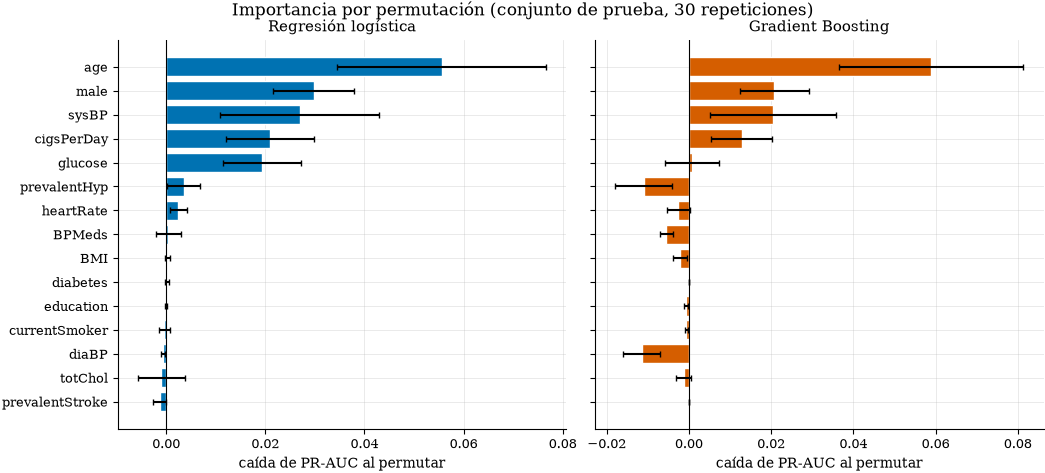

,Regresión logística,Gradient Boosting
age,5.560e-02,5.890e-02
male,2.980e-02,2.070e-02
sysBP,2.690e-02,2.040e-02
cigsPerDay,2.090e-02,1.280e-02
glucose,1.930e-02,8.000e-04
prevalentHyp,3.600e-03,-1.100e-02
heartRate,2.500e-03,-2.600e-03
BPMeds,4.000e-04,-5.500e-03
BMI,3.000e-04,-2.200e-03
diabetes,2.000e-04,0.000e+00


In [31]:
importancias = {}
for n in ["Regresión logística", no_lineal]:
    r = permutation_importance(finales[n], X_test, y_test, scoring="average_precision",
                               n_repeats=30, random_state=SEED, n_jobs=-1)
    importancias[n] = pd.DataFrame({"caída media de PR-AUC": r.importances_mean, "DE": r.importances_std},
                                   index=X_test.columns)

orden = importancias["Regresión logística"]["caída media de PR-AUC"].sort_values().index
fig, ax = plt.subplots(1, 2, figsize=(10.5, 4.6), sharey=True)
for a, n in zip(ax, importancias):
    d = importancias[n].loc[orden]
    a.barh(d.index, d["caída media de PR-AUC"], xerr=d["DE"], color=COLORES[n], edgecolor="white", capsize=2)
    a.axvline(0, color="black", lw=0.8)
    a.set_title(n)
    a.set_xlabel("caída de PR-AUC al permutar")
fig.suptitle("Importancia por permutación (conjunto de prueba, 30 repeticiones)", y=1.03)
guardar(fig, "18-importancia-permutacion.png")

tabla_imp = pd.concat({n: d["caída media de PR-AUC"] for n, d in importancias.items()}, axis=1).sort_values("Regresión logística", ascending=False)
tabla_imp.to_csv(TABLE_DIR / "p2-importancia-permutacion.csv")
tabla_imp.round(4)

La importancia por permutación confirma lo anterior y añade una comparación entre modelos:

* **Ambos modelos coinciden en las mismas cuatro variables principales**: edad (la más importante por
  amplio margen, con una caída de PR-AUC cercana a 0,06), sexo, presión sistólica y cigarrillos por
  día. La logística agrega la glucosa en quinto lugar (0,019); en Gradient Boosting su aporte es casi
  nulo (0,001).
* **Las otras diez variables tienen una importancia muy pequeña (≤ 0,004) o indistinguible de cero**
  en la logística. Entre ellas están el colesterol total, la diabetes, la hipertensión previa, el IMC
  y la presión diastólica: su información ya está contenida en las variables principales o es
  demasiado débil.
* En Gradient Boosting, varias de esas variables tienen valores negativos (`diaBP` −0,012,
  `prevalentHyp` −0,011): permutarlas *mejoró* levemente la PR-AUC, señal de que para ese modelo
  agregan ruido.
* `prevalentStroke` no puede evaluarse en prueba: solo hay 3 casos y ninguno desarrolló el evento.

Que un modelo lineal y uno de árboles, con mecanismos tan distintos, coincidan en las mismas
variables indica que el resultado **no depende de la elección del modelo**: es una propiedad de los
datos.

## 10. Análisis de errores

Se examinan las predicciones del modelo final en el conjunto de prueba, separadas en sus cuatro
tipos: verdaderos positivos (VP), falsos negativos (FN), falsos positivos (FP) y verdaderos
negativos (VN). Los falsos negativos son el error más relevante en tamizaje: personas que
desarrollaron enfermedad coronaria y que el modelo no habría marcado.

In [32]:
p_final, t_final = proba[modelo_final], umbrales[modelo_final]
pred_final = (p_final >= t_final).astype(int)
tipo = np.select([(yt == 1) & (pred_final == 1), (yt == 1) & (pred_final == 0),
                  (yt == 0) & (pred_final == 1), (yt == 0) & (pred_final == 0)], ["VP", "FN", "FP", "VN"],
                 default="")

perfil = X_test.assign(prob=p_final, tipo=tipo)
cols = ["age", "sysBP", "glucose", "totChol", "BMI", "cigsPerDay", "male", "prevalentHyp", "diabetes", "BPMeds", "prob"]
errores = perfil.groupby("tipo")[cols].mean().reindex(["VP", "FN", "FP", "VN"])
errores.insert(0, "n", perfil["tipo"].value_counts().reindex(errores.index))
errores.to_csv(TABLE_DIR / "p2-analisis-errores.csv")
errores.round(2)

,n,age,sysBP,glucose,totChol,BMI,cigsPerDay,male,prevalentHyp,diabetes,BPMeds,prob
tipo,,,,,,,,,,,,
VP,103,55.22,146.30,91.12,245.13,26.87,10.92,0.65,0.59,0.08,0.06,0.26
FN,26,42.96,120.19,74.57,224.00,24.39,12.46,0.38,0.12,0.00,0.00,0.07
FP,363,54.45,141.35,84.63,250.29,26.40,9.39,0.52,0.48,0.03,0.06,0.21
VN,356,42.67,119.23,77.07,221.41,24.74,7.68,0.28,0.07,0.00,0.01,0.06


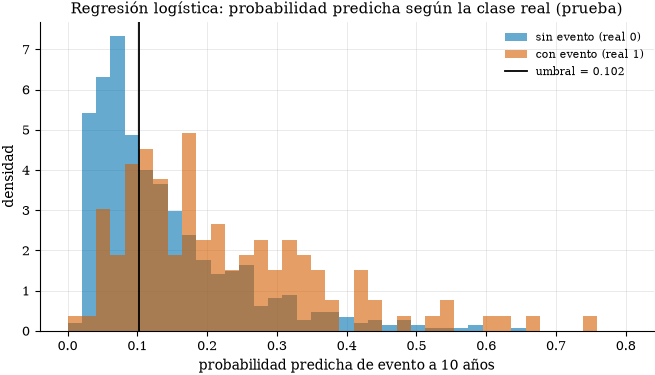

In [33]:
fig, ax = plt.subplots(figsize=(6.6, 3.8))
bins = np.linspace(0, max(p_final.max(), 0.8), 40)
ax.hist(p_final[yt == 0], bins=bins, alpha=0.6, color="#0072B2", density=True, label="sin evento (real 0)")
ax.hist(p_final[yt == 1], bins=bins, alpha=0.6, color="#D55E00", density=True, label="con evento (real 1)")
ax.axvline(t_final, color="black", lw=1.3, label=f"umbral = {t_final:.3f}")
ax.set_xlabel("probabilidad predicha de evento a 10 años")
ax.set_ylabel("densidad")
ax.set_title(f"{modelo_final}: probabilidad predicha según la clase real (prueba)")
ax.legend(fontsize=8)
guardar(fig, "19-probabilidades-por-clase.png")

El perfil de cada tipo de error explica por qué el modelo no puede hacerlo mucho mejor:

* **Los 26 falsos negativos se parecen a los verdaderos negativos, no a los verdaderos positivos.**
  Tienen en promedio 43,0 años, 120 mm Hg de presión sistólica y 74,6 mg/dL de glucosa; el 38 % son
  hombres, el 12 % es hipertenso y ninguno tiene diabetes. Los verdaderos negativos tienen 42,7 años,
  119 mm Hg y un 7 % de hipertensos. Estas personas desarrollaron enfermedad coronaria **sin
  presentar los factores de riesgo clásicos en el examen basal** (su probabilidad media predicha es
  0,07). No es tanto un fallo del modelo como un límite de la información: con estas variables no son
  distinguibles. Su riesgo pudo depender de factores no medidos (colesterol HDL, antecedentes
  familiares) o de cambios ocurridos durante los 10 años de seguimiento.
* **Los 363 falsos positivos se parecen a los verdaderos positivos.** Tienen 54,5 años en promedio,
  141 mm Hg y un 48 % de hipertensos (frente a 55,2 años, 146 mm Hg y 59 % en los verdaderos
  positivos). Son personas con riesgo real que no desarrollaron el evento en la ventana de 10 años,
  ya sea por azar, por tratamiento o porque el evento ocurrió más tarde.

El histograma lo resume: las probabilidades de los casos con evento están desplazadas a la derecha,
pero ambas distribuciones se superponen ampliamente entre 0,05 y 0,30, y cualquier umbral en esa
zona intercambia un tipo de error por el otro. Mejorar el tamizaje requeriría **información nueva**,
no un modelo más flexible. Es la misma conclusión que surge de que los modelos de árboles no superen
a la logística.

## 11. Equidad: desempeño por subgrupo

Se desagrega el desempeño del modelo final por sexo y por nivel educativo (proxy socioeconómico).
Con pocos eventos por subgrupo, las diferencias pueden deberse al azar; por eso cada recall se
acompaña de su intervalo de confianza por *bootstrap* dentro del subgrupo.

In [34]:
def por_grupo(col, etiquetas):
    filas = []
    g_rng = np.random.default_rng(SEED)
    for valor, etiqueta in etiquetas.items():
        m = (X_test[col] == valor).to_numpy()
        yg, pg = yt[m], pred_final[m]
        pos, neg = np.flatnonzero(yg == 1), np.flatnonzero(yg == 0)
        rec_boot = [recall_score(yg[ix], pg[ix]) for ix in
                    (np.r_[g_rng.choice(pos, len(pos)), g_rng.choice(neg, len(neg))] for _ in range(2000))]
        filas.append({"variable": col, "grupo": etiqueta, "n": int(m.sum()), "eventos": int(yg.sum()),
                      "% eventos": 100 * yg.mean(), "recall": recall_score(yg, pg),
                      "IC 95 % recall": "[{:.2f}, {:.2f}]".format(*np.percentile(rec_boot, [2.5, 97.5])),
                      "precision": precision_score(yg, pg, zero_division=0),
                      "% marcados": 100 * pg.mean(),
                      "prob. media predicha": p_final[m].mean(),
                      "ROC-AUC": roc_auc_score(yg, p_final[m])})
    return filas


equidad = pd.DataFrame(por_grupo("male", {0: "mujeres", 1: "hombres"}) +
                       por_grupo("education", {1.0: "educación 1", 2.0: "educación 2", 3.0: "educación 3", 4.0: "educación 4"})
                       ).set_index(["variable", "grupo"])
equidad.to_csv(TABLE_DIR / "p2-equidad.csv")
equidad.round(3)

n  eventos  % eventos  recall IC 95 % recall  \
variable  grupo                                                         
male      mujeres      482       52     10.788   0.692   [0.58, 0.81]   
          hombres      366       77     21.038   0.870   [0.79, 0.94]   
education educación 1  337       65     19.288   0.908   [0.83, 0.97]   
          educación 2  267       37     13.858   0.649   [0.49, 0.78]   
          educación 3  133       10      7.519   0.700   [0.40, 1.00]   
          educación 4   88       12     13.636   0.750   [0.50, 1.00]   

                       precision  % marcados  prob. media predicha  ROC-AUC  
variable  grupo                                                              
male      mujeres          0.171      43.568                 0.124    0.683  
          hombres          0.262      69.945                 0.183    0.682  
education educación 1      0.255      68.546                 0.182    0.697  
          educación 2      0.205      43.820                 0.126    0.689  
          educación 3      0.121      43.609                 0.119    0.679  
          educación 4      0.205      50.000                 0.129    0.647

**Por sexo, el modelo ordena igual de bien, pero detecta menos casos en mujeres.** La ROC-AUC es
prácticamente idéntica en ambos sexos (0,683 y 0,682): el modelo distingue a quienes desarrollarán
el evento con la misma calidad en hombres y en mujeres. Aun así, el recall en mujeres es **0,69**
[0,58–0,81] frente a **0,87** [0,79–0,94] en hombres, y su precisión también es menor (0,17 frente
a 0,26).

La brecha no se debe a un peor desempeño del modelo, sino a aplicar **un único umbral a dos grupos
con riesgo base distinto**. Las mujeres de la muestra tienen una tasa de eventos del 10,8 % (frente
al 21,0 % en hombres), y el modelo, correctamente calibrado, les asigna probabilidades más bajas
(media 0,12 frente a 0,18). Por eso muchas menos superan el umbral de 0,102: se marca al 44 % de las
mujeres y al 70 % de los hombres, incluidas mujeres que sí desarrollarán el evento. En la práctica,
un umbral único reproduce en parte la menor detección de enfermedad coronaria en mujeres documentada
en la literatura clínica [12].

Una alternativa sería usar umbrales distintos por sexo para igualar el recall. Esa opción tiene sus
propios costos (más falsos positivos en mujeres y el uso explícito del sexo en la decisión), y
corresponde a una decisión clínica y ética, no técnica. Se documenta aquí para que esa decisión
pueda tomarse con información.

**Por nivel educativo**, el recall va de 0,91 en el nivel 1 a 0,65 en el nivel 2, siguiendo el mismo
mecanismo: el nivel 1 tiene la tasa de eventos más alta (19,3 %), la mayor probabilidad media
predicha (0,18) y es el más marcado (69 %). Los niveles 3 y 4 tienen solo 10 y 12 eventos en prueba,
con intervalos de recall tan amplios ([0,40–1,00] y [0,50–1,00]) que no permiten ninguna conclusión.
La ROC-AUC es similar en todos los niveles (0,65–0,70). Además, `education` tiene una OR cercana a 1
y una importancia nula: el modelo casi no la usa, y las diferencias por nivel provienen de los
factores de riesgo correlacionados con ella (edad, sexo, tabaquismo).

## 12. Síntesis y respuesta a las preguntas de investigación

**Pregunta 1. ¿Qué variables de un chequeo de rutina discriminan mejor el riesgo coronario a 10 años?**
La **edad**, el **sexo**, la **presión sistólica**, los **cigarrillos por día** y, en menor medida,
la **glucosa**. Las dos formas de medir la importancia (razones de *odds* de la logística e
importancia por permutación de dos modelos distintos) coinciden, y estas variables coinciden con la
mayoría de los factores de los scores de riesgo clásicos de Framingham. El estatus de fumador no
aporta casi nada una vez conocida la dosis, y la presión diastólica no aporta riesgo una vez conocida
la sistólica. El colesterol total, el IMC, la diabetes y la hipertensión previa aportan poco por
encima de las variables principales (en el caso del colesterol, posiblemente porque falta el HDL con
el que suele combinarse). La edad sola ya discrimina bastante (ROC-AUC 0,638 en prueba), pero las
demás variables aportan una mejora estadísticamente significativa (+0,064 de ROC-AUC).

**Pregunta 2. ¿Un modelo lineal basta, o los no lineales mejoran el desempeño?**
**El modelo lineal basta, y es el mejor.** La regresión logística obtiene la mayor PR-AUC en
validación cruzada (0,365 frente a 0,356 y 0,343) y en prueba (0,302 frente a 0,275 en ambos), y una
ROC-AUC mayor en prueba (0,702 frente a 0,680 y 0,670; la ventaja es significativa frente a Gradient
Boosting y marginal frente a Random Forest). Con el mismo número de falsas alarmas, detecta entre 8 y
10 eventos más. La validación cruzada prefirió configuraciones simples de los modelos de árboles: hay
poca estructura no lineal que aprovechar. Random Forest y Gradient Boosting son **equivalentes**
entre sí; Gradient Boosting solo tiene ventajas operativas (más rápido y con manejo nativo de
faltantes). La presión de pulso, como ingeniería de características, no cambia el desempeño de la
logística y aporta muy poco a los árboles. Este resultado coincide con
una revisión sistemática de modelos de predicción clínica, que no encontró ventajas de desempeño del
machine learning sobre la regresión logística [13].

**Pregunta 3. ¿Cómo afectan el desbalance, los faltantes y los subgrupos?**
* *Desbalance*: ponderar las clases empeora o no cambia la PR-AUC y descalibra gravemente las
  probabilidades (la media predicha pasa de 0,15 a 0,39–0,44). Tratarlo con el umbral de decisión
  mantiene el modelo calibrado (probabilidad media 0,149 frente a una prevalencia de 0,152) y logra
  un recall de 0,80 en prueba, al costo de marcar al 55 % de las personas.
* *Faltantes*: la estrategia de imputación no influye en el desempeño (mediana global, por sexo o
  manejo nativo de `NaN`: diferencias ≤ 0,001 de PR-AUC).
* *Equidad*: la discriminación es la misma en hombres y mujeres, pero con un umbral único el recall
  es menor en mujeres (0,69 frente a 0,87).

**Modelo final.** Regresión logística con regularización L2 (`C = 0,1`), sin ponderación de clases y
con umbral de decisión 0,102. En prueba: ROC-AUC 0,702 [0,653–0,746], PR-AUC 0,302 [0,237–0,380],
recall 0,80, precisión 0,22 y Brier 0,121.

**Limitaciones principales** (a desarrollar en el informe): una sola cohorte de mediados del
siglo XX, predominantemente blanca y de una única localidad, sin validación externa; un único
*split* de prueba con 129 eventos; un umbral fijado con un criterio (F2) que responde a una
preferencia por el recall, no a un análisis de costos real; y la ausencia de variables relevantes
para el riesgo coronario, como el colesterol HDL o los antecedentes familiares, que limita el techo
de desempeño de cualquier modelo.

## Referencias

[1] L. Breiman, "Random forests," *Machine Learning*, vol. 45, no. 1, pp. 5–32, 2001.

[2] J. H. Friedman, "Greedy function approximation: A gradient boosting machine," *Annals of
Statistics*, vol. 29, no. 5, pp. 1189–1232, 2001.

[3] G. Ke *et al.*, "LightGBM: A highly efficient gradient boosting decision tree," en *Advances in
Neural Information Processing Systems 30 (NeurIPS)*, 2017.

[4] N. V. Chawla, K. W. Bowyer, L. O. Hall y W. P. Kegelmeyer, "SMOTE: Synthetic minority
over-sampling technique," *Journal of Artificial Intelligence Research*, vol. 16, pp. 321–357, 2002.

[5] R. van den Goorbergh, M. van Smeden, D. Timmerman y B. Van Calster, "The harm of class imbalance
corrections for risk prediction models: illustration and simulation using logistic regression,"
*Journal of the American Medical Informatics Association*, vol. 29, no. 9, pp. 1525–1534, 2022.

[6] T. Saito y M. Rehmsmeier, "The precision-recall plot is more informative than the ROC plot when
evaluating binary classifiers on imbalanced datasets," *PLoS ONE*, vol. 10, no. 3, e0118432, 2015.

[7] B. Van Calster, D. J. McLernon, M. van Smeden, L. Wynants y E. W. Steyerberg, "Calibration: the
Achilles heel of predictive analytics," *BMC Medicine*, vol. 17, 230, 2019.

[8] B. Efron y R. J. Tibshirani, *An Introduction to the Bootstrap*. Chapman & Hall/CRC, 1993.

[9] Validaciones externas del Framingham Risk Score reportan AUC (c-statistic) entre 0,70 y 0,78 en
distintas cohortes; ver la referencia [2] del notebook `01-eda.ipynb`.

[10] P. W. F. Wilson, R. B. D'Agostino, D. Levy, A. M. Belanger, H. Silbershatz y W. B. Kannel,
"Prediction of coronary heart disease using risk factor categories," *Circulation*, vol. 97, no. 18,
pp. 1837–1847, 1998.

[11] R. B. D'Agostino Sr. *et al.*, "General cardiovascular risk profile for use in primary care: the
Framingham Heart Study," *Circulation*, vol. 117, no. 6, pp. 743–753, 2008.

[12] B. Vogel *et al.*, "The Lancet women and cardiovascular disease Commission: reducing the global
burden by 2030," *The Lancet*, vol. 397, no. 10292, pp. 2385–2438, 2021.

[13] E. Christodoulou, J. Ma, G. S. Collins, E. W. Steyerberg, J. Y. Verbakel y B. Van Calster, "A
systematic review shows no performance benefit of machine learning over logistic regression for
clinical prediction models," *Journal of Clinical Epidemiology*, vol. 110, pp. 12–22, 2019.
